<h1 style="color:#C22308; font-weight:bold; font-size:2.5em">1. Introduction</h1>



In this project, we focus on the implementation and analysis of the Support Vector Machine (SVM) algorithm for binary classification tasks. SVM is a powerful and widely used model whose objective is to find the optimal decision boundary that separates two classes while maximizing the margin between them. This property often leads to strong generalization performance, especially in high-dimensional datasets.

Rather than relying exclusively on external libraries, this work emphasizes the understanding of the mathematical foundations behind the algorithm by developing a custom implementation from scratch in Python. The model is based on the soft-margin linear SVM formulation, using hinge loss and gradient-based optimization to learn the parameters of the separating hyperplane.

The project also includes data preprocessing, model training, prediction, and performance evaluation using appropriate classification metrics.
The main objectives of this project are:

- To study the theoretical principles of Support Vector Machines;
- To implement a linear soft-margin SVM classifier from scratch in Python;
- To understand the role of hinge loss, regularization, and gradient descent optimization;
- To evaluate the model on real classification datasets;
- To compare theoretical expectations with practical results.

This report presents the theoretical background, implementation details, optimization procedure, experimental methodology, and obtained results.

In [ ]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")


In [2]:
datasets = [
    'dataset_38_sick.csv',
    'dataset_311_oil_spill.csv',
    'dataset_312_scene.csv',
    'dataset_316_yeast_ml8.csv',
    'dataset_450_analcatdata_lawsuit.csv',
    'dataset_463_backache.csv',
    'dataset_757_meta.csv',
    'dataset_764_analcatdata_apnea3.csv',
    'dataset_765_analcatdata_apnea2.csv',
    'dataset_767_analcatdata_apnea1.csv',
    'dataset_865_analcatdata_neavote.csv',
    'dataset_867_visualizing_livestock.csv',
    'dataset_875_analcatdata_chlamydia.csv',
    'dataset_940_water-treatment.csv',
    'dataset_947_arsenic-male-bladder.csv',
    'dataset_949_arsenic-female-bladder.csv',
    'dataset_950_arsenic-female-lung.csv',
    'dataset_951_arsenic-male-lung.csv',
    'dataset_954_spectrometer.csv',
    'dataset_958_segment.csv',
    'dataset_962_mfeat-morphological.csv',
    'dataset_966_analcatdata_halloffame.csv',
    'dataset_968_analcatdata_birthday.csv',
    'dataset_971_mfeat-fourier.csv',
    'dataset_976_JapaneseVowels.csv',
    'dataset_978_mfeat-factors.csv',
    'dataset_980_optdigits.csv',
    'dataset_984_analcatdata_draft.csv',
    'dataset_987_collins.csv',
    'dataset_995_mfeat-zernike.csv',
    'dataset_1000_hypothyroid.csv',
    'dataset_1002_ipums_la_98-small.csv',
    'dataset_1004_synthetic_control.csv',
    'dataset_1013_analcatdata_challenger.csv',
    'dataset_1014_analcatdata_dmft.csv',
    'dataset_1016_vowel.csv',
    'dataset_1018_ipums_la_99-small.csv',
    'dataset_1020_mfeat-karhunen.csv',
    'dataset_1021_page-blocks.csv',
    'dataset_1022_mfeat-pixel.csv',
    'dataset_1023_soybean.csv',
    'dataset_1039_hiva_agnostic.csv',
    'dataset_1045_kc1-top5.csv',
    'dataset_1049_pc4.csv',
    'dataset_1050_pc3.csv',
    'dataset_1056_mc1.csv',
    'dataset_1059_ar1.csv',
    'dataset_1061_ar4.csv',
    'dataset_1064_ar6.csv',
    'dataset_1065_kc3.csv'
]

<h1 style="color:#C22308; font-weight:bold; font-size:2.5em">2. SVM Implementation</h1>

<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">2.1 Theory behind</h1>

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.1.1 Problem Formulation</h1>


Given a set of pairs $\mathbf{(x_i,y_i)}$, where $\mathbf{x_i}$ is the feature vector of sample $\mathbf{i}$ and $\mathbf{y_i}$ its class label, the goal of our Support Vector Machine is to learn a decision boundary that separates the two classes, while maximazing the margin between them defined as $\mathbf{w} \cdot \mathbf{x} + b = 0$, where $\mathbf{x}$ represents any point in the feature space, $\mathbf{w}$ the vector of corresponding weights and $b$ the bias.

For any sample $\mathbf{x}$, the model calculates the score function (its position relative to the frontier):
$$f(x) = \mathbf{w} \cdot \mathbf{x} + b$$

- If \(f(x) > 0\), the sample lies on the positive side of the boundary;
- If \(f(x) < 0\), the sample lies on the negative side of the boundary;
- If \(f(x) = 0\), the sample lies exactly on the decision boundary.

The product of the object's known target and the linear function's result, $\mathbf{y_i} \cdot f(\mathbf{x_i})$, defines the margin of the classification:
- positive values greater than 1, $\mathbf{y_i} \cdot f(\mathbf{x_i}) > 1$ mean the object is classified as belonging to its actual class and outside the margin;
- values between 0 and 1; $0 < \mathbf{y_i} \cdot f(\mathbf{x_i}) < 1$, mean the object is correctly classified but inside the margin;
- negative values, $\mathbf{y_i} \cdot f(\mathbf{x_i}) < 0$ mean the object is misclassifed.

For any given point $\mathbf{x}_i$, its distance to the frontier is:

$$d_i = \frac{y_i(\mathbf{w} \cdot \mathbf{x_i} + b)}{\|\mathbf{w}\|}$$

where a positive value means the point is correctly classified and its magnitude reflects how far it is from the frontier. We aim to maximize the margin, which is equivalent to minimizing $\|\mathbf{w}\|^2$, or more conviniently $1/2\|\mathbf{w}\|^2$. However, in real-world datasets, data is rarely linearly separable, so we introduce slack variables $\xi_i \geq 0$ that allow points to violate the margin:

$$\min_{\mathbf{w}, b, \boldsymbol{\xi}} \frac{1}{2}\|\mathbf{w}\|^2 + C\sum_i \xi_i \quad \text{given} \quad y_i(\mathbf{w} \cdot \mathbf{x}_i + b) \geq 1 - \xi_i, \quad \xi_i \geq 0$$

The parameter $C$ controls the trade-off between maximizing the margin and minimizing margin violations. The slack variables $\xi_i$ measure the degree of misclassification:
- $\xi_i = 0$ means the point is correctly classified and outside the margin;
-  $\xi_i \in ]0, 1]$ means it is correctly classified but inside the margin;
-  $\xi_i > 1$ indicates a misclassified point.  

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.1.2 Hinge Loss Function</h1>


Instead of explicitly optimizing the constrained formulation above, our implementation uses the equivalent unconstrained formulation based on hinge loss:

$$
J(\mathbf{w}, b)=\frac{1}{2}\|\mathbf{w}\|^2 + C \sum_{i=1}^{n}\max\left(0, 1 - y_i(\mathbf{w}^T\mathbf{x}_i+b)\right)
$$

In this formulation, the hinge loss term:

$$
\max\left(0, 1-y_i(\mathbf{w}^T\mathbf{x}_i+b)\right)
$$

is equivalent to the slack variable penalty, since:

$$
\xi_i = \max\left(0, 1-y_i(\mathbf{w}^T\mathbf{x}_i+b)\right)
$$

Thus, although slack variables are not explicitly stored in the code, they are implicitly represented through the hinge loss.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.1.3 Gradient Descent Optimization</h1>


The model parameters are learned by minimizing the objective function:

$$
J(\mathbf{w},b)=\frac{1}{2}\|\mathbf{w}\|^2 + C\max\left(0,1-y_i(\mathbf{w}^T\mathbf{x}_i+b)\right)
$$

Since the hinge loss is not differentiable at every point, our implementation uses subgradient descent. For each training sample, we compute:

$$
f(\mathbf{x}_i)=\mathbf{w}^T\mathbf{x}_i+b$$
and:
$$y_i f(\mathbf{x}_i)=y_i(\mathbf{w}^T\mathbf{x}_i+b)
$$

This determines which gradient must be applied.



#### *Case 1: Correctly classified and outside the margin*

If:

$$
y_i(\mathbf{w}^T\mathbf{x}_i+b)\geq1
$$

then:

$$
\max(0,1-y_i(\mathbf{w}^T\mathbf{x}_i+b))=0
$$

So the objective reduces to:

$$
J(\mathbf{w},b)=\frac{1}{2}\|\mathbf{w}\|^2
$$

The gradients are:

$$
\frac{\partial J}{\partial \mathbf{w}}=\mathbf{w}
$$

$$
\frac{\partial J}{\partial b}=0
$$

Therefore, the updates become:

$$
\mathbf{w}\leftarrow \mathbf{w}-\eta\mathbf{w}
$$

$$
b\leftarrow b
$$


#### *Case 2: Misclassified or inside the margin*

If:

$$
y_i(\mathbf{w}^T\mathbf{x}_i+b)<1
$$

then:

$$
J(\mathbf{w},b)=\frac{1}{2}\|\mathbf{w}\|^2 + C(1-y_i(\mathbf{w}^T\mathbf{x}_i+b))
$$

Now the gradients are:

$$
\frac{\partial J}{\partial \mathbf{w}}=\mathbf{w}-Cy_i\mathbf{x}_i
$$

$$
\frac{\partial J}{\partial b}=-Cy_i
$$

Applying gradient descent:

$$
\mathbf{w}\leftarrow \mathbf{w}-\eta(\mathbf{w}-Cy_i\mathbf{x}_i)
$$

$$
b\leftarrow b-\eta(-Cy_i)
$$

which simplifies to:

$$
b\leftarrow b+\eta Cy_i
$$


<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">2.2 Our Implementation</h1>
With all the previous information in mind, we built the following model.

In [3]:
class SVM:
    #Inicar o o modelo com os hiperparâmetros
    def __init__(self, learning_rate=0.01, C=1.0, n_iters=1000):
        self.learning_rate = learning_rate
        self.C = C
        self.n_iters = n_iters
        self.w = None #array de pesos
        self.b = None #bias

    def fit(self, X, y):

        #Identifica quais são as duas labels originais
        self.classes = np.unique(y)
        #Converte temporariamente para -1 e 1 para o treino
        y_labels = np.where(y == self.classes[0], -1, 1)

        #Pegar no número de amostras (linhas) e de features(colunas)
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0


        self.train(X, y_labels)

    def train(self, X, y):
        for _ in range(self.n_iters):
            indices = np.random.permutation(len(X))

            for i in indices:
                x_i = X[i]
                y_i = y[i]

                linear_output = self.decision_function(x_i)

                correct_side = y_i * linear_output

                if correct_side >= 1:
                    self.w -= self.learning_rate * self.w
                else:
                    self.w -= self.learning_rate * (self.w - self.C * y_i * x_i)
                    self.b += self.learning_rate * self.C * y_i

    def decision_function(self, X):
      return np.dot(X, self.w) + self.b


    def predict(self, X):
      linear_output = self.decision_function(X)
      return np.where(linear_output >= 0, self.classes[1],self.classes[0])  #se linear_output for maior ou igual a 0, a classe é 1, se for menor que 0, a classe é 0



<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">2.3 Label Preparation and Evaluation Metrics</h1>


In order to ensure consistency across all experiments and maintain compatibility with the mathematical formulation of the Support Vector Machine, a set of auxiliary functions was implemented.

Firstly, since the SVM formulation assumes binary labels in the set $\{-1, +1\}$, a preprocessing step is required to convert the original class labels into this representation. The `prepare_labels` function performs this transformation automatically, while also storing a mapping to later recover the original labels for interpretation and visualization purposes.

Secondly, to evaluate the performance of the model without relying on external libraries, custom implementations of standard evaluation metrics were developed. These include:

- A manually computed **confusion matrix**, which allows direct access to True Positives, True Negatives, False Positives, and False Negatives.
- A visualization function for the confusion matrix, which maps predictions back to the original class labels for better interpretability.
- A custom **classification report**, where precision, recall, and F1-score are computed explicitly for each class.


Precision, recall, and F1-score were chosen because accuracy alone can be misleading in imbalanced datasets. These metrics provide a more informative evaluation of the model’s performance.

Precision measures the reliability of positive predictions, recall evaluates the model’s ability to detect each class, and F1-score balances both. The accuracy metric will also be reported to prove how unreliable its use is in imbalance datasets such as the ones explored later on.



It is important to note that metrics are calculated **individually for each class**, rather than using aggregated values. This design choice is particularly relevant in the context of **class imbalance**, as it provides a more detailed understanding of the model's behavior on both majority and minority classes.


In [4]:

def prepare_labels(df, target_col):
    # Guardar labels originais
    original_classes = sorted(df[target_col].unique())

    # Criar mapping automático
    label_map = {
        original_classes[0]: -1,
        original_classes[1]: 1
    }

    inverse_map = {
        -1: original_classes[0],
         1: original_classes[1]
    }

    # Aplicar transformação
    df[target_col] = df[target_col].map(label_map)

    return df, inverse_map


def my_confusion_matrix(y_true, y_pred):


  TP = np.sum((y_true == 1) & (y_pred == 1))
  TN = np.sum((y_true <= 0) & (y_pred <= 0))
  FP = np.sum((y_true <= 0) & (y_pred == 1))
  FN = np.sum((y_true == 1) & (y_pred <= 0))

  return [[TN, FP], [FN, TP]]


def print_confusion_matrix(y_true, y_pred, inverse_map):
    cm = confusion_matrix(y_true, y_pred)

    # usar labels reais
    classes = np.unique(y_true)
    class_names = [inverse_map[c] for c in classes]

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)

    plt.title('Matriz de Confusão')
    plt.xlabel("Previsão")
    plt.ylabel("Real")
    plt.tight_layout()
    plt.show()
    print("="*60)



def class_report(y_true, y_pred):
    classes = np.unique(y_true)

    for cls in classes:
        TP = np.sum((y_true == cls) & (y_pred == cls))
        FP = np.sum((y_true != cls) & (y_pred == cls))
        FN = np.sum((y_true == cls) & (y_pred != cls))

        precision = TP / (TP + FP) if (TP + FP) > 0 else 0
        recall    = TP / (TP + FN) if (TP + FN) > 0 else 0
        f1 = (2 * precision * recall / (precision + recall)
              if (precision + recall) > 0 else 0)

        print(f"Classe {cls}")
        print(f" Precision: {precision:.2f}")
        print(f" Recall:    {recall:.2f}")
        print(f" F1-score:  {f1:.2f}")
        print()

<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">2.4 Transition from Primal SVM to the Dual Formulation (Motivation for Kernels)</h1>

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.4.1. Initial Implementation</h1>

The SVM we implemented is based on the following decision function:

$$
f(x) = w^T x + b
$$

where:
- $w$ is the weight vector (**one weight per feature**),
- $x$ is the input, represented by a vector of features.
- $b$ is the bias term, wich allows the decision function on a point other than 0.

The cost function is defined using the hinge loss, as explained previusly:

$$
J(w, b) = \frac{1}{2} ||w||^2 + C \sum_i \max(0, 1 - y_i (w^T x_i + b))
$$

This formulation directly optimizes the parameters $w$ and $b$.

The model learns **how important each feature is** for the classification task.

---
<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.4.2 Limitation</h1>


In this initial implementation, the decision function depends mostly on:

$$
w^T x
$$

(with $b$ acting as a constant offset)

This means the model can only learn **linear decision boundaries in the space of the original features**.

However, most real-world problems are not linearly separable in this space. Capturing more complex relationships would require explicitly transforming the data into a higher-dimensional space, which can be computationally expensive or impractical.

---
<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.4.3 Key Idea Behind the Transition</h1>


To bypass this limitation we can rewrite the weight vector $w$ as a linear combination of the training data:

$$
w = \sum_i \alpha_i y_i x_i
$$

where:
- $\alpha_i$ are coefficients to be learned,
- $y_i$ are the labels,
- $x_i$ are the training samples.

This represents a drastic change in the model:

- instead of learning **weights per feature ($w$)**,
- we now learn **weights per training example ($\alpha_i$)**.

Substituting this expression into the decision function:

$$
f(x) = w^T x + b = \left( \sum_i \alpha_i y_i x_i \right)^T x + b
$$

$$
f(x) = \sum_i \alpha_i y_i (x_i^T x) + b
$$

The **bias term $b$ remains unchanged** and continues to act as a "shift" of the decision boundary.

---

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.4.4 New Interpretation of the Model</h1>



The model no longer depends explicitly on $w$, but instead on:
- all training points $x_i$,
- their corresponding coefficients $\alpha_i$,
- and the bias term $b$.

Each $\alpha_i$ determines **how much influence one specific training point has** on the decision boundary, while $b$ controls its position.

This means:
- in the initial format → we weight features,
- in the new format → we weight data points.

The prediction is now based on a **weighted sum of similarities between the input and the training data**, plus a bias offset.

---
<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.4.5 Introducing the Kernel</h1>


Notice that the model depends only on inner products:

$$
x_i^T x
$$

This allows us to replace the product with a kernel function:

$$
K(x_i, x)
$$

which leads to:

$$
f(x) = \sum_i \alpha_i y_i K(x_i, x) + b
$$

---

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.4.6 The importance of the Kernel</h1>


A kernel function allows us to compute inner products in a higher-dimensional space **without explicitly mapping the data to that space**.

In this project we are going to implement the widly known Radial Basis Function (RBF) kernel, as it's one of the most used nowadays.

This makes it possible to learn **non-linear decision boundaries efficiently**.

---

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.4.7 New Loss Function</h1>


Even though the model representation changes, the base of our hinge loss function remaains basicly the same. The difference is that both the decision function and the regularization term are now expressed in terms of the coefficients $\alpha_i$.

Starting from our previous regularization term:

$$
\frac{1}{2} ||w||^2
$$

and substituting:

$$
w = \sum_i \alpha_i y_i x_i
$$

we obtain:

$$
||w||^2 = w^T w = \left( \sum_i \alpha_i y_i x_i \right)^T \left( \sum_j \alpha_j y_j x_j \right)
$$

which expands to:

$$
||w||^2 = \sum_{i,j} \alpha_i \alpha_j y_i y_j (x_i^T x_j)
$$

Replacing the dot product with a kernel function:

$$
x_i^T x_j \rightarrow K(x_i, x_j)
$$

the full loss function becomes:

$$
J(\alpha, b) = \frac{1}{2} \sum_{i,j} \alpha_i \alpha_j y_i y_j K(x_i, x_j) + C \sum_i \max(0, 1 - y_i f(x_i))
$$

where:

$$
f(x_i) = \sum_j \alpha_j y_j K(x_j, x_i) + b
$$

This shows that the regularization term, originally defined in terms of $w$, is now expressed as a function of pairwise interactions between training points. The hinge loss term itself remains unchanged, continuing to penalize points that lie inside the margin or are misclassified.misclassified.

---


<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">2.4.8 Gradients Computation</h1>




### *Case 1: Correctly classified and outside the margin*

If:

$$
y_i f(x_i) \geq 1
$$

then:

$$
J(\alpha) = \frac{1}{2} \sum_{i,j} \alpha_i \alpha_j y_i y_j K(x_i, x_j)
$$



#### Gradient with respect to $\alpha_k$

We isolate the terms involving $\alpha_k$:

$$
\frac{\partial J}{\partial \alpha_k}
= \frac{\partial}{\partial \alpha_k}
\left(
\frac{1}{2} \sum_{i,j} \alpha_i \alpha_j y_i y_j K(x_i, x_j)
\right)
$$

Differentiating:

$$
\frac{\partial J}{\partial \alpha_k}
= \sum_j \alpha_j y_k y_j K(x_k, x_j)
$$



#### Gradient with respect to $b$

Since $b$ does not appear in this case:

$$
\frac{\partial J}{\partial b} = 0
$$

---

### *Case 2: Misclassified or inside the margin*

If:

$$
y_i f(x_i) < 1
$$

then:

$$
J(\alpha, b) =
\frac{1}{2} \sum_{i,j} \alpha_i \alpha_j y_i y_j K(x_i, x_j)
+ C(1 - y_i f(x_i))
$$



#### Gradient with respect to $\alpha_k$

Split into two parts:

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">1. Regularization term:</h1>



$$
\frac{\partial}{\partial \alpha_k}
\left(
\frac{1}{2} \sum_{i,j} \alpha_i \alpha_j y_i y_j K(x_i, x_j)
\right)
=
\sum_j \alpha_j y_k y_j K(x_k, x_j)
$$

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">2. Hinge loss term:</h1>


Recall:

$$
f(x_i) = \sum_j \alpha_j y_j K(x_j, x_i) + b
$$

So:

$$
\frac{\partial}{\partial \alpha_k} (-C y_i f(x_i))
= -C y_i \frac{\partial f(x_i)}{\partial \alpha_k}
$$

Only one term depends on $\alpha_k$:

$$
\frac{\partial f(x_i)}{\partial \alpha_k}
= y_k K(x_k, x_i)
$$

Thus:

$$
\frac{\partial}{\partial \alpha_k} (-C y_i f(x_i))
= -C y_i y_k K(x_k, x_i)
$$

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">3. Final gradient:</h1>


$$
\frac{\partial J}{\partial \alpha_k}
=
\sum_j \alpha_j y_k y_j K(x_k, x_j)
- C y_i y_k K(x_k, x_i)
$$


#### Gradient with respect to $b$

Only hinge term depends on $b$:

$$
\frac{\partial}{\partial b} (-C y_i f(x_i)) = -C y_i
$$

So:

$$
\frac{\partial J}{\partial b} = -C y_i
$$

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">4. Final Update Rules:</h1>


$$
\alpha_k \leftarrow \alpha_k - \eta \left[
\sum_j \alpha_j y_k y_j K(x_k, x_j)
- C y_i y_k K(x_k, x_i)
\right]
$$

$$
b \leftarrow b + \eta C y_i
$$

---



In [5]:


class KERNEL_SVM(BaseEstimator, ClassifierMixin):
    def __init__(self, learning_rate=0.0001, C=1.0, n_iters=100, gamma=0.1):
        self.learning_rate = learning_rate
        self.C = C
        self.n_iters = n_iters
        self.gamma = gamma
        self.alpha = None
        self.b = 0
        self.X = None
        self.y = None

    def _compute_kernel_matrix(self, X1, X2):
        # (a-b)^2 = a^2 + b^2 - 2ab
        sq_norm1 = np.sum(X1**2, axis=1).reshape(-1, 1)
        sq_norm2 = np.sum(X2**2, axis=1).reshape(1, -1)
        distances = sq_norm1 + sq_norm2 - 2 * np.dot(X1, X2.T)
        return np.exp(-self.gamma * distances)

    def fit(self, X, y):

        n_samples = X.shape[0]
        self.classes = np.unique(y)
        # Converte classes originais para -1 e 1
        y_labels = np.where(y == self.classes[0], -1, 1)

        self.X = X
        self.y = y_labels
        self.alpha = np.zeros(n_samples)
        self.b = 0

        #Cálculo da Matriz de Kernel
        K = self._compute_kernel_matrix(X, X)


        for _ in range(self.n_iters):
            for i in range(n_samples):
                # 1. Calcula da previsao atual
                prediction = np.sum(self.alpha * self.y * K[:, i]) + self.b

                # Calcula o Gradiente da Regularização
                # grad_reg = sum(alpha_j * y_i * y_j * K_ij)
                # Nota: y_i * (prediction - b) é matematicamente equivalente a essa soma
                grad_reg = self.y[i] * (prediction - self.b)

                # 3. Aplica as regras de atualização baseadas nos Casos 1 e 2 do relatório
                if self.y[i] * prediction < 1:
                    #Misclassified or inside margin
                    # grad_alpha = grad_reg - C * y_i * y_i * K(i,i) -> simplifica para grad_reg - C
                    grad_alpha = grad_reg - self.C
                    self.b += self.learning_rate * self.C * self.y[i]
                else:
                    # Caso 1: Correctly classified and outside margin
                    grad_alpha = grad_reg

                # Atualização do parâmetro alpha_k
                self.alpha[i] -= self.learning_rate * grad_alpha

                # Restrição teórica do SVM: alpha >= 0
                self.alpha[i] = max(0, self.alpha[i])
        self.fitted_ = True
        return self


    def predict(self, X_test):
        # Kernel entre os dados de teste e os dados de treino
        K_test = self._compute_kernel_matrix(X_test, self.X)
        predictions = np.dot(K_test, self.alpha * self.y) + self.b
        return np.where(predictions >= 0, self.classes[1], self.classes[0])

<h1 style="color:#C22308; font-weight:bold; font-size:2.5em">3. Expirimental Setup</h1>


The results show that every dataset presents a high level of class imbalance, with most majority class ratios well above 0.8. This indicates that, in most cases, one class strongly dominates the dataset.

Overall, this distribution confirms that class imbalance is a consistent characteristic across the datasets used, reinforcing the need for techniques such as weighted learning to ensure that minority classes are properly considered during training.

<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">3.1 Dataset Processing Strategy</h1>


In this project, we evaluate our model across multiple datasets to ensure robustness under different data distributions and levels of class imbalance.

Each dataset is processed using a standardized procedure:

- The dataset is loaded using `pandas`
- The **features** are defined as all columns except the last:
  
$$
X = \text{all columns except last}
$$

- The **target variable** is defined as the last column:

$$
y = \text{last column}
$$

This approach ensures consistency in all the datasets regardless of their structure.

---
<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">3.2 Automatic Preprocessing Pipeline</h1>


To handle diferent types of data (numerical and categorical), we use a **ColumnTransformer**, which applies different preprocessing steps depending on the data type.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">3.2.1 Numerical Features</h1>


For numerical attributes, we apply:

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">1. Missing value imputation (median)</h1>

   
$$
x_{\text{missing}} \rightarrow \text{median}(x)
$$

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">2. Standardization (zero mean, unit variance)</h1>


$$
x' = \frac{x - \mu}{\sigma}
$$

This ensures that all numerical features contribute equally to the model.

---
<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">3.2.2 Categorical Features</h1>


For categorical attributes, we apply:

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">1. Missing value imputation (median)</h1>
   
Missing values are replaced with a constant label `"missing"`.

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">2. One-Hot Encoding</h1>


Each category is transformed into a binary vector:

$$
\text{Category} \rightarrow [0,0,1,0,...]
$$

This allows the model to process categorical data numerically.

In [7]:
def get_svm_pipeline(model_instance):
    # Pipeline para números
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Pipeline para texto
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    # Seletor inteligente de colunas
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, make_column_selector(dtype_exclude=object)),
            ('cat', categorical_transformer, make_column_selector(dtype_include=object))
        ])

    # Retorna o pipeline completo (Preprocessamento + Modelo)
    return Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model_instance)
    ])

<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">3.3 Class Imbalance Visualization</h1>


The following plot represents the level of class imbalance across all datasets by displaying the proportion of the majority class in each case.

For each dataset, the ratio is computed as:

$$
\text{Majority Ratio} = \frac{\text{Number of samples in the majority class}}{\text{Total number of samples}}
$$

This measure provides a consistent way to quantify imbalance, independently of which class is labeled as positive or negative.

A value close to 0.5 indicates a balanced dataset, where both classes are equally represented. As the ratio approaches 1, it indicates increasing imbalance, meaning that one class dominates the dataset.

The dashed horizontal line at 0.5 serves as a reference for perfect balance.

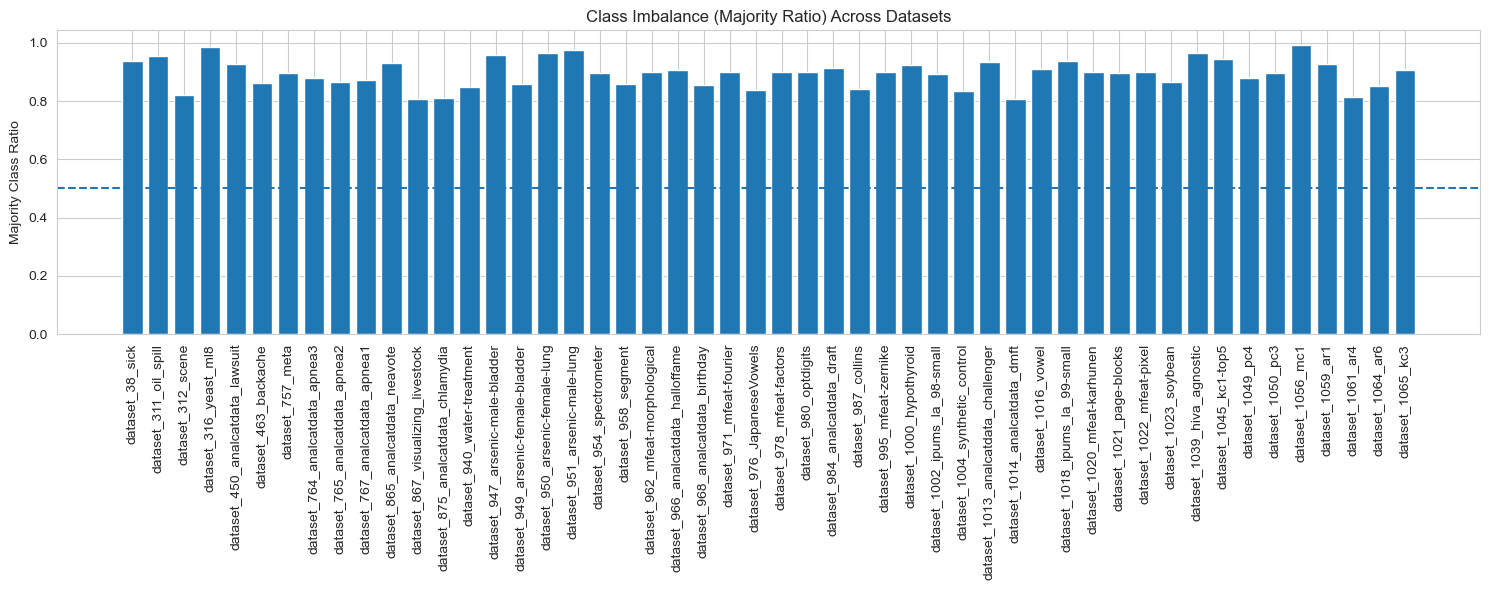

In [15]:
dataset_names = []
majority_ratios = []

for path in datasets:
    df = pd.read_csv(path)
    y = df.iloc[:, -1]

    classes = y.unique()

    if len(classes) != 2:
        continue  # ignorar multiclass

    counts = y.value_counts()

    majority = counts.max()
    total = counts.sum()

    ratio = majority / total

    dataset_names.append(path.split("/")[-1].replace(".csv",""))
    majority_ratios.append(ratio)


# plot
x = np.arange(len(dataset_names))

plt.figure(figsize=(15,6))
plt.bar(x, majority_ratios)

plt.axhline(0.5, linestyle='--')  # equilíbrio

plt.xticks(x, dataset_names, rotation=90)
plt.ylabel("Majority Class Ratio")
plt.title("Class Imbalance (Majority Ratio) Across Datasets")

plt.tight_layout()
plt.show()

<h1 style="color:#C22308; font-weight:bold; font-size:2.5em">4. Standard SVM — Analysis</h1>

<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">4.1 Results</h1>


In [8]:
results = []

# Configuração do Loop
for path in datasets:
    print(f"\n" + "="*50)
    print(f"ANALISANDO DATASET: {path}")

    try:
        # Carregar o dataset
        df = pd.read_csv(path)

        # Separar X e y (última coluna)
        X = df.iloc[:, :-1]
        y = df.iloc[:, -1]

        # Instanciar o modelo
        model_svm = KERNEL_SVM(learning_rate=0.001, C=10.0, gamma = 0.1, n_iters=100)

        clf = get_svm_pipeline(model_svm)

        # Split
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

        # Treino
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        # Gerar o report em dicionário para extrair dados para a tabela
        report_dict = classification_report(y_test, y_pred, output_dict=True)

        # Identificar classes para definir Minoritária vs Majoritária
        class_names = [k for k in report_dict.keys() if k not in ['accuracy', 'macro avg', 'weighted avg']]
        sorted_classes = sorted(class_names, key=lambda c: report_dict[c]['support'])

        minority_class = sorted_classes[0]
        majority_class = sorted_classes[-1] if len(sorted_classes) > 1 else sorted_classes[0]

        # 4. GUARDAR RESULTADOS
        results.append({
            'Dataset': path.split('/')[-1],
            'Accuracy': report_dict['accuracy'],
            'Macro_F1': report_dict['macro avg']['f1-score'],
            'Minority_F1': report_dict[minority_class]['f1-score'],
            'Minority_Class': minority_class,
            # Dados extras para a tabela
            'Min_Precision': report_dict[minority_class]['precision'],
            'Min_Recall': report_dict[minority_class]['recall'],
            'Maj_Precision': report_dict[majority_class]['precision'],
            'Maj_Recall': report_dict[majority_class]['recall'],
            'Maj_F1': report_dict[majority_class]['f1-score']
        })

        print(f"Dataset {path.split('/')[-1]} processado.")

    except Exception as e:
        print(f"[ERRO] Falha no dataset {path}: {e}")

# --- APÓS O LOOP: CRIAR O DATAFRAME COM O NOME QUE OS TEUS GRÁFICOS USAM ---
df_final_results = pd.DataFrame(results)






ANALISANDO DATASET: dataset_38_sick.csv
Dataset dataset_38_sick.csv processado.

ANALISANDO DATASET: dataset_311_oil_spill.csv
Dataset dataset_311_oil_spill.csv processado.

ANALISANDO DATASET: dataset_312_scene.csv
Dataset dataset_312_scene.csv processado.

ANALISANDO DATASET: dataset_316_yeast_ml8.csv
Dataset dataset_316_yeast_ml8.csv processado.

ANALISANDO DATASET: dataset_450_analcatdata_lawsuit.csv
Dataset dataset_450_analcatdata_lawsuit.csv processado.

ANALISANDO DATASET: dataset_463_backache.csv
Dataset dataset_463_backache.csv processado.

ANALISANDO DATASET: dataset_757_meta.csv
Dataset dataset_757_meta.csv processado.

ANALISANDO DATASET: dataset_764_analcatdata_apnea3.csv
Dataset dataset_764_analcatdata_apnea3.csv processado.

ANALISANDO DATASET: dataset_765_analcatdata_apnea2.csv
Dataset dataset_765_analcatdata_apnea2.csv processado.

ANALISANDO DATASET: dataset_767_analcatdata_apnea1.csv
Dataset dataset_767_analcatdata_apnea1.csv processado.

ANALISANDO DATASET: dataset

In [17]:
# Transformar em DataFrame
df_final_results = pd.DataFrame(results)

# Mostrar a tabela

display(df_final_results.sort_values(by='Minority_F1', ascending=False).round(3).style.hide(axis='index'))
'''''
# Gerar o gráfico com os dados
if not df_final_results.empty:
    plt.figure(figsize=(10, 6))
    df_plot = df_final_results.melt(id_vars='Dataset', value_vars=['Accuracy', 'Minority_F1'],
                                    var_name='Metric', value_name='Score')
    sns.boxplot(x='Metric', y='Score', data=df_plot, palette="Set2")
    plt.title('Performance Distribution (Partial Results)')
    plt.show()
'''''

Dataset,Accuracy,Macro_F1,Minority_F1,Minority_Class,Min_Precision,Min_Recall,Maj_Precision,Maj_Recall,Maj_F1
dataset_951_arsenic-male-lung.csv,1.000000,1.000000,1.000000,N,1.000000,1.000000,1.000000,1.000000,1.000000
dataset_962_mfeat-morphological.csv,1.000000,1.000000,1.000000,P,1.000000,1.000000,1.000000,1.000000,1.000000
dataset_1016_vowel.csv,1.000000,1.000000,1.000000,P,1.000000,1.000000,1.000000,1.000000,1.000000
dataset_958_segment.csv,0.996000,0.991000,0.985000,P,0.985000,0.985000,0.997000,0.997000,0.997000
dataset_976_JapaneseVowels.csv,0.991000,0.983000,0.972000,P,0.981000,0.963000,0.993000,0.996000,0.995000
dataset_1004_synthetic_control.csv,0.983000,0.969000,0.947000,P,1.000000,0.900000,0.980000,1.000000,0.990000
dataset_995_mfeat-zernike.csv,0.985000,0.957000,0.923000,P,0.947000,0.900000,0.989000,0.994000,0.992000
dataset_1021_page-blocks.csv,0.975000,0.932000,0.877000,N,0.897000,0.857000,0.984000,0.989000,0.986000
dataset_1023_soybean.csv,0.971000,0.929000,0.875000,P,1.000000,0.778000,0.967000,1.000000,0.983000
dataset_980_optdigits.csv,0.975000,0.923000,0.860000,P,1.000000,0.754000,0.973000,1.000000,0.986000


'\'\'\n# Gerar o gráfico com os dados\nif not df_final_results.empty:\n    plt.figure(figsize=(10, 6))\n    df_plot = df_final_results.melt(id_vars=\'Dataset\', value_vars=[\'Accuracy\', \'Minority_F1\'],\n                                    var_name=\'Metric\', value_name=\'Score\')\n    sns.boxplot(x=\'Metric\', y=\'Score\', data=df_plot, palette="Set2")\n    plt.title(\'Performance Distribution (Partial Results)\')\n    plt.show()\n'

<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">4.2 Analysis of Experimental Results</h1>

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">4.2.1 Overview of Findings</h1>

After running the model through all the datasets, a very clear pattern emerged regarding how our SVM behaves. At first glance, the results look impressive because the accuracy is frequently above 90%. However, once we started analysing the **Macro F1** and **Minority F1** scores, the model's true limitations became obvious. The gap between high accuracy and poor minority detection really highlights just how sensitive this implementation is to class imbalance.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">4.2.2 The Accuracy Problem</h1>


One of the most important takeaways from this experiment is that high accuracy doesn't always mean a good model. We noticed several cases where the accuracy was between **0.85 and 0.95**, but the **Minority Recall and F1 were exactly zero**.

In this scenario, the model achieves high performance by predominantly predicting the majority class, disregarding the minority class. As a result, the reported accuracy is inflated and fails to reflect the model’s true predictive capability. This highlights that, in the presence of class imbalance, accuracy is a misleading metric.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">4.2.3 Performance by Groups</h1>


When looking at the **Minority F1-score**, the datasets generally fell into three distinct categories:

*   **Group 1: High Performers (F1 ≥ 0.9)**
    In datasets like *vowel*, *mfeat-morphological*, and *JapaneseVowels*, the model performed exceptionally well. In these cases, the data was either not so imbalanced or the classes were so distinct that the SVM had no trouble drawing a clear decision boundary. The model generalizes beautifully here because it doesn't have to fight against a dominant majority class.

*   **Group 2: The Conservative Models (F1 between 0.3 and 0.9)**
    In datasets such as *sick*, *page-blocks*, and *collins*, we see a more "cautious" behavior. The model usually has high precision but much lower recall. This means that when the model actually predicts the minority class, it’s usually right—but it misses a huge chunk of the actual minority cases. It’s clear that the decision boundary is being pushed too far toward the majority side.
*   **Group 3: Total Minority Collapse (F1 = 0)**
    This was the most problematic group, including datasets like *scene*, *yeast_ml8*, *backache*, and *kc3*. Here, the model completely gave up on the minority class. It effectively collapsed into a majority-only classifier, never once predicting the minority class.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">4.2.4 Bias and the Precision–Recall Trade-off</h1>

The bias toward the majority class is undeniable. In some tests, the **Majority Recall was near 1.00**, meaning the model almost never misses a majority case. Interestingly, when the model did manage to predict a minority case, the **Minority Precision** was often quite high. This shows the model is "scared" to predict the minority class unless it is absolutely certain, leading to that massive drop in recall.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">4.2.5 Why Macro F1 Matters</h1>


This is exactly why we focused on the **Macro F1** score. Unlike standard accuracy, Macro F1 treats both classes as equally important. In balanced datasets, the Macro F1 and Accuracy are almost identical, but in imbalanced ones, the Macro F1 drops significantly. It acts as a "reality check" that penalizes the model for ignoring the smaller class.

---

Ultimately, these results prove that while the SVM implementation is mathematically correct, it isn't naturally robust against uneven class distributions. Without an extra mechanism to balance the scales, the model will always favor the majority to minimize global loss. This is the main motivation for the next part of my project, where I’ll explore **class weighting** to try forcing the model to pay more attention to these underrepresented chunks of data.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">4.2.6 Macro and Minority F1 Analysis </h1>


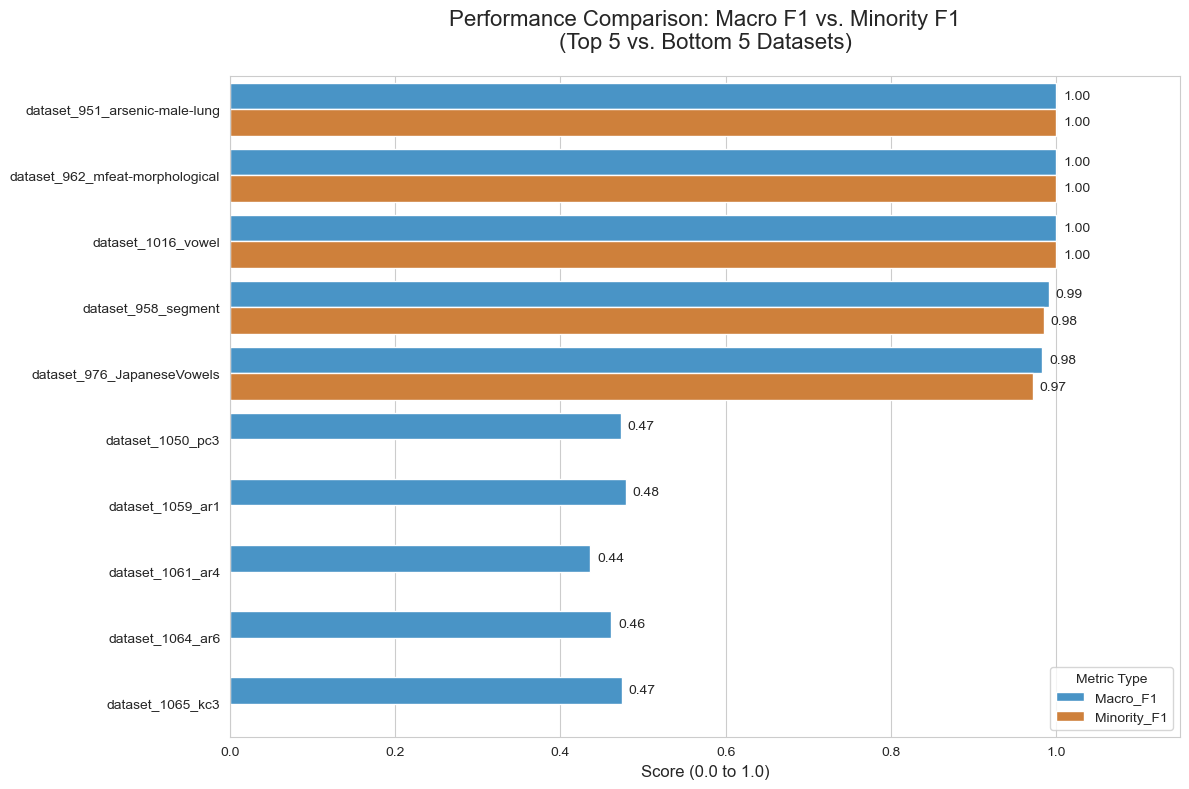

In [11]:
# 1. Selecionar Top 5 e Bottom 5 baseados no Minority_F1
df_sorted = df_final_results.sort_values(by='Minority_F1', ascending=False)
top_bottom = pd.concat([df_sorted.head(5), df_sorted.tail(5)]).copy()

# Limpar nomes dos datasets
top_bottom['Dataset'] = top_bottom['Dataset'].str.replace('.csv', '', regex=False)

# 2. "Melt" (Derreter) o DataFrame: transforma as colunas Macro e Minority em linhas
# Isso é necessário para o Seaborn criar as barras agrupadas (hue)
df_plot = top_bottom.melt(
    id_vars='Dataset',
    value_vars=['Macro_F1', 'Minority_F1'],
    var_name='Metric',
    value_name='Score'
)

# 3. Criar o Gráfico
plt.figure(figsize=(12, 8))
sns.set_style("whitegrid")

ax = sns.barplot(
    data=df_plot,
    x='Score',
    y='Dataset',
    hue='Metric',
    palette={'Macro_F1': '#3498db', 'Minority_F1': '#e67e22'} # Azul vs Laranja
)

# Adicionar os valores nas barras
for p in ax.patches:
    width = p.get_width()
    if width > 0: # Só mostrar se o valor for maior que 0
        ax.annotate(f'{width:.2f}',
                    (width, p.get_y() + p.get_height() / 2),
                    ha='left', va='center',
                    xytext=(5, 0),
                    textcoords='offset points',
                    fontsize=10)

# 4. Ajustes Finais
plt.title('Performance Comparison: Macro F1 vs. Minority F1\n(Top 5 vs. Bottom 5 Datasets)', fontsize=16, pad=20)
plt.xlabel('Score (0.0 to 1.0)', fontsize=12)
plt.ylabel('')
plt.xlim(0, 1.15)
plt.legend(title='Metric Type', loc='lower right')
plt.tight_layout()

plt.show()

This bar chart allows us to visualize the behaviour studied before, more specificly the diference between the "Group 1" and "Group 3" that we talked about just now. It illustrates the contrast between **Macro F1** and **Minority F1** scores across the highest and lowest performing datasets.

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">1.Top 5 Datasets</h1>

In the top-performing datasets, such as *Challenger* and *Vowel*, both metrics reach near-unity (**1.00**). This alignment confirms that the **RBF Kernel** and the **gradient descent optimization** are mathematically sound. When classes are sufficiently represented or well-separated, the model successfully identifies patterns in both categories without bias.

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">2. Majority Class Bias (Bottom 5 Datasets)</h1>

The bottom-performing datasets, including *mc1* and *ar1*, exhibit a complete collapse of the **Minority F1** score (0.00), while the **Macro F1** stabilizes near **0.50**. This specific signature indicates a total reliance on the majority class:
*   The model achieves a perfect score on the majority class but fails to identify any minority instances.
*   The resulting 0.50 Macro F1 reflects the unweighted average of these two extremes.
*   The absence of the orange bars (Minority F1) reveals that high global accuracy in these cases is purely a byproduct of class imbalance rather than predictive power.

---

<h1 style="color:#C22308; font-weight:bold; font-size:2.5em">5. Weighted SVM — Implementation & Analysis</h1>

As we just saw, the model exhibited a significant bias toward majority classes. In several instances, the SVM achieved high global accuracy by simply "ignoring" the minority class (resulting in a 0.00 Minority F1-score).

Our standard **Loss** function treats every misclassification with the same penalty ($C$). In an imbalanced scenario, the optimization process finds it "cheaper" to misclassify a few minority samples than to risk shifting the decision boundary and misclassifying a larger number of majority samples. To solve this, we must introduce **Class Weights** to force the model to prioritize the underrepresented class.

<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">5.1 Our Implementation</h1>


The core idea is to transform the global penalty parameter $C$ into a sample-specific penalty $C_i$, where $C_i = C \times \text{weight}_i$.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">5.1.1 Calculating the Weights</h1>

We implemented the "balanced" heuristic, which assigns weights inversely proportional to class frequencies:
$$W_j = \frac{N}{k \cdot n_j}$$
Where:
- $N$ is the total number of samples.
- $k$ is the number of classes (2).
- $n_j$ is the number of samples in class $j$.

This ensures that a sample from a rare class carries significantly more weight in the cost function than a sample from a common class.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">5.1.2 Modified Gradient Update</h1>

The most important change happens within the training loop. The penalty for violating the margin is now scaled by the class weight:

```python
# Effective penalty for the current sample
Ci = self.C * weights[i]

if y_labels[i] * prediction < 1:
    # The gradient update is now driven by Ci instead of a global C
    grad_alpha = grad_reg - Ci
    self.b += self.learning_rate * Ci * y_labels[i]
```
<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">5.1.3 Impact on Optimization</h1>

When the model encounters a minority sample:
1.  **Increased Gradient:** Because $C_i$ is much larger for rare classes, the `grad_alpha` becomes a larger negative value.
2.  **Aggressive Alpha Update:** Since $\alpha_i$ is updated via `alpha[i] -= learning_rate * grad_alpha`, the coefficient for that specific minority point rises rapidly.
3.  **Support Vector Priority:** This forces the minority point to become a highly influential **Support Vector**, effectively "pushing" the decision boundary to include it correctly, even at the cost of a slightly smaller margin for the majority class.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">5.1.4 Expected Outcome</h1>

By implementing this weighted approach, the model is no longer allowed to ignore rare cases. We expect a slight decrease in overall **Accuracy**, but a significant increase in **Minority Recall** and **Macro F1-score**. This trade-off is essential for real-world applications (like medical diagnosis) where missing a minority case is far more costly than a majority-class false alarm.

In [10]:
class KERNEL_SVM_W(BaseEstimator, ClassifierMixin):
    def __init__(self, learning_rate=0.0001, C=1.0, n_iters=100, gamma=0.1, class_weight = 'balanced'):
        self.learning_rate = learning_rate
        self.C = C
        self.n_iters = n_iters
        self.gamma = gamma
        self.alpha = None
        self.b = 0
        self.X = None
        self.y = None
        self.class_weight = class_weight

    def _compute_kernel_matrix(self, X1, X2):
        # (a-b)^2 = a^2 + b^2 - 2ab
        sq_norm1 = np.sum(X1**2, axis=1).reshape(-1, 1)
        sq_norm2 = np.sum(X2**2, axis=1).reshape(1, -1)
        distances = sq_norm1 + sq_norm2 - 2 * np.dot(X1, X2.T)
        return np.exp(-self.gamma * distances)

    def fit(self, X, y):

        n_samples = X.shape[0]
        self.classes = np.unique(y)
        # Converte classes originais para -1 e 1
        y_labels = np.where(y == self.classes[0], -1, 1)

        self.X = X
        self.y = y_labels
        self.alpha = np.zeros(n_samples)
        self.b = 0

        #Pesos por classe

        weights = np.ones(n_samples)

        if self.class_weight == 'balanced':
            count = np.bincount(np.where(y_labels == -1, 0, 1))

            weight_minus = n_samples / (2.0 * count[0])
            weight_plus = n_samples / (2.0 * count[1])

            weights = np.where(y_labels == -1, weight_minus, weight_plus)

        #Cálculo da Matriz de Kernel
        K = self._compute_kernel_matrix(X, X)


        for _ in range(self.n_iters):
            for i in range(n_samples):

                # Calcular o C da amostra
                ci = self.C * weights[i]

                # 1. Calcula da previsao atual
                prediction = np.sum(self.alpha * self.y * K[:, i]) + self.b

                # Calcula o Gradiente da Regularização
                # grad_reg = sum(alpha_j * y_i * y_j * K_ij)
                # Nota: y_i * (prediction - b) é matematicamente equivalente a essa soma
                grad_reg = self.y[i] * (prediction - self.b)

                # 3. Aplica as regras de atualização baseadas nos Casos 1 e 2 do relatório
                if self.y[i] * prediction < 1:
                    #Misclassified or inside margin
                    # grad_alpha = grad_reg - C * y_i * y_i * K(i,i) -> simplifica para grad_reg - C
                    grad_alpha = grad_reg - ci
                    self.b += self.learning_rate * ci * self.y[i]
                else:
                    # Caso 1: Correctly classified and outside margin
                    grad_alpha = grad_reg

                # Atualização do parâmetro alpha_k
                self.alpha[i] -= self.learning_rate * grad_alpha

                # Restrição teórica do SVM: alpha >= 0
                self.alpha[i] = max(0, self.alpha[i])

        self.fitted_ = True
        return self

    def predict(self, X_test):
        # Kernel entre os dados de teste e os dados de treino
        K_test = self._compute_kernel_matrix(X_test, self.X)
        predictions = np.dot(K_test, self.alpha * self.y) + self.b
        return np.where(predictions >= 0, self.classes[1], self.classes[0])

<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">5.2 Analysis of Experimental Results</h1>


With the theoretical motivation established and the implementation in place, we now turn to the results. The following analysis examines whether the weighted formulation delivers on its promise — and at what cost.

In [13]:
results_new = []

# Configuração do Loop
for path in datasets:
    #print(f"\n" + "="*50)
    #print(f"ANALISANDO DATASET: {path}")

    try:
        # Carregar o dataset
        df = pd.read_csv(path)

        # Separar X e y (última coluna)
        X = df.iloc[:, :-1]
        y = df.iloc[:, -1]

        # Instanciar o modelo com os teus parâmetros
        model_svm_w = KERNEL_SVM_W(learning_rate=0.001, C=10.0, n_iters=100,gamma=0.005, class_weight = 'balanced')

        clf = get_svm_pipeline(model_svm_w)

        # Split
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, #stratisfy=y
                                                            )

        # Treino
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        # Gerar o report em dicionário para extrair dados para a tabela
        report_dict = classification_report(y_test, y_pred, output_dict=True)

        # Identificar classes para definir Minoritária vs Majoritária
        class_names = [k for k in report_dict.keys() if k not in ['accuracy', 'macro avg', 'weighted avg']]
        sorted_classes = sorted(class_names, key=lambda c: report_dict[c]['support'])

        minority_class = sorted_classes[0]
        majority_class = sorted_classes[-1] if len(sorted_classes) > 1 else sorted_classes[0]

        # 4. GUARDAR RESULTADOS
        results_new.append({
            'Dataset': path.split('/')[-1],
            'Accuracy': report_dict['accuracy'],
            'Macro_F1': report_dict['macro avg']['f1-score'],
            'Minority_F1': report_dict[minority_class]['f1-score'],
            'Minority_Class': minority_class,
            # Dados extras para a tabela
            'Min_Precision': report_dict[minority_class]['precision'],
            'Min_Recall': report_dict[minority_class]['recall'],
            'Maj_Precision': report_dict[majority_class]['precision'],
            'Maj_Recall': report_dict[majority_class]['recall'],
            'Maj_F1': report_dict[majority_class]['f1-score']
        })

        print(f"Dataset {path.split('/')[-1]} processado.")

    except Exception as e:
        print(f"[ERRO] Falha no dataset {path}: {e}")

# --- APÓS O LOOP: CRIAR O DATAFRAME COM O NOME QUE OS TEUS GRÁFICOS USAM ---
df_final_results_new = pd.DataFrame(results_new)

Dataset dataset_38_sick.csv processado.
Dataset dataset_311_oil_spill.csv processado.
Dataset dataset_312_scene.csv processado.
Dataset dataset_316_yeast_ml8.csv processado.
Dataset dataset_450_analcatdata_lawsuit.csv processado.
Dataset dataset_463_backache.csv processado.
Dataset dataset_757_meta.csv processado.
Dataset dataset_764_analcatdata_apnea3.csv processado.
Dataset dataset_765_analcatdata_apnea2.csv processado.
Dataset dataset_767_analcatdata_apnea1.csv processado.
Dataset dataset_865_analcatdata_neavote.csv processado.
Dataset dataset_867_visualizing_livestock.csv processado.
Dataset dataset_875_analcatdata_chlamydia.csv processado.
Dataset dataset_940_water-treatment.csv processado.
Dataset dataset_947_arsenic-male-bladder.csv processado.
Dataset dataset_949_arsenic-female-bladder.csv processado.
Dataset dataset_950_arsenic-female-lung.csv processado.
Dataset dataset_951_arsenic-male-lung.csv processado.
Dataset dataset_954_spectrometer.csv processado.
Dataset dataset_958_

In [26]:
# Mostrar a tabela
display(df_final_results_new.sort_values(by='Minority_F1', ascending=False).round(3).style.hide(axis='index'))

# Gerar o gráfico com os dados
'''''
if not df_final_results_new.empty:
    plt.figure(figsize=(10, 6))
    df_plot = df_final_results_new.melt(id_vars='Dataset', value_vars=['Accuracy', 'Minority_F1'],
                                    var_name='Metric', value_name='Score')
    sns.boxplot(x='Metric', y='Score', data=df_plot, palette="Set2")
    plt.title('Performance Distribution (Partial Results)')
    plt.show()
'''''

Dataset,Accuracy,Macro_F1,Minority_F1,Minority_Class,Min_Precision,Min_Recall,Maj_Precision,Maj_Recall,Maj_F1
dataset_1004_synthetic_control.csv,1.000000,1.000000,1.000000,P,1.000000,1.000000,1.000000,1.000000,1.000000
dataset_978_mfeat-factors.csv,0.998000,0.992000,0.986000,P,0.973000,1.000000,1.000000,0.997000,0.999000
dataset_962_mfeat-morphological.csv,0.998000,0.992000,0.986000,P,1.000000,0.972000,0.997000,1.000000,0.999000
dataset_971_mfeat-fourier.csv,0.998000,0.992000,0.986000,P,1.000000,0.972000,0.997000,1.000000,0.999000
dataset_1020_mfeat-karhunen.csv,0.998000,0.992000,0.986000,P,1.000000,0.972000,0.997000,1.000000,0.999000
dataset_1022_mfeat-pixel.csv,0.998000,0.992000,0.986000,P,1.000000,0.972000,0.997000,1.000000,0.999000
dataset_980_optdigits.csv,0.993000,0.981000,0.966000,P,0.974000,0.958000,0.995000,0.997000,0.996000
dataset_958_segment.csv,0.989000,0.975000,0.957000,P,0.948000,0.965000,0.995000,0.993000,0.994000
dataset_995_mfeat-zernike.csv,0.988000,0.961000,0.930000,P,0.943000,0.917000,0.992000,0.995000,0.993000
dataset_951_arsenic-male-lung.csv,0.991000,0.952000,0.909000,N,1.000000,0.833000,0.991000,1.000000,0.995000


'\'\'\nif not df_final_results_new.empty:\n    plt.figure(figsize=(10, 6))\n    df_plot = df_final_results_new.melt(id_vars=\'Dataset\', value_vars=[\'Accuracy\', \'Minority_F1\'],\n                                    var_name=\'Metric\', value_name=\'Score\')\n    sns.boxplot(x=\'Metric\', y=\'Score\', data=df_plot, palette="Set2")\n    plt.title(\'Performance Distribution (Partial Results)\')\n    plt.show()\n'

Rather than walking through each dataset row by row — which would be both tedious and hard to draw conclusions from — we chose to focus on four visualizations that we believe give a much clearer picture of what is actually happening across all 50 datasets. 

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">5.2.1 Precision vs Recall: Boundary shift</h1>

In [ ]:


# --- Preparar dados ---
df_comp = pd.merge(
    df_final_results[['Dataset', 'Min_Precision', 'Min_Recall', 'Minority_F1']],
    df_final_results_new[['Dataset', 'Min_Precision', 'Min_Recall', 'Minority_F1']],
    on='Dataset',
    suffixes=('_Std', '_W')
)
df_comp['Dataset'] = df_comp['Dataset'].str.replace('.csv', '', regex=False)
df_comp['improved'] = df_comp['Minority_F1_W'] > df_comp['Minority_F1_Std']

fig = go.Figure()

# --- Linhas de iso-F1 ---
recall_vals = np.linspace(0.01, 1.0, 300)
for f1_target, dash, opacity in [(0.3, 'dot', 0.4), (0.5, 'dash', 0.5), (0.7, 'dashdot', 0.6)]:
    precision_vals = (f1_target * recall_vals) / (2 * recall_vals - f1_target + 1e-9)
    mask = (precision_vals >= 0) & (precision_vals <= 1)
    fig.add_trace(go.Scatter(
        x=recall_vals[mask],
        y=precision_vals[mask],
        mode='lines',
        line=dict(color='rgba(100,100,100,0.4)', dash=dash, width=1),
        name=f'F1 = {f1_target}',
        hoverinfo='skip'
    ))
    # Label no fim da curva
    idx = np.where(mask)[0][-1]
    fig.add_annotation(
        x=recall_vals[idx], y=precision_vals[idx],
        text=f'F1={f1_target}',
        showarrow=False,
        font=dict(size=9, color='grey'),
        xshift=18
    )

# --- Setas ---
for _, row in df_comp.iterrows():
    color = '#27ae60' if row['improved'] else '#e74c3c'

    fig.add_trace(go.Scatter(
        x=[row['Min_Recall_Std'], row['Min_Recall_W']],
        y=[row['Min_Precision_Std'], row['Min_Precision_W']],
        mode='lines',
        line=dict(color=color, width=1.5),
        showlegend=False,
        hoverinfo='skip'
    ))

    fig.add_trace(go.Scatter(
        x=[row['Min_Recall_Std']],
        y=[row['Min_Precision_Std']],
        mode='markers',
        marker=dict(color='#95a5a6', size=7, symbol='circle'),
        showlegend=False,
        hovertemplate=(
            f"<b>{row['Dataset']}</b><br>"
            f"Model: Standard SVM<br>"
            f"Recall: {row['Min_Recall_Std']:.3f}<br>"
            f"Precision: {row['Min_Precision_Std']:.3f}<br>"
            f"F1: {row['Minority_F1_Std']:.3f}<extra></extra>"
        )
    ))

    fig.add_trace(go.Scatter(
        x=[row['Min_Recall_W']],
        y=[row['Min_Precision_W']],
        mode='markers',
        marker=dict(color=color, size=9, symbol='arrow', angleref='previous'),
        showlegend=False,
        hovertemplate=(
            f"<b>{row['Dataset']}</b><br>"
            f"Model: Weighted SVM<br>"
            f"Recall: {row['Min_Recall_W']:.3f}<br>"
            f"Precision: {row['Min_Precision_W']:.3f}<br>"
            f"F1: {row['Minority_F1_W']:.3f}<extra></extra>"
        )
    ))

# --- Legendas manuais ---
fig.add_trace(go.Scatter(x=[None], y=[None], mode='markers',
    marker=dict(color='#27ae60', size=10), name='Improved (F1 ↑)'))
fig.add_trace(go.Scatter(x=[None], y=[None], mode='markers',
    marker=dict(color='#e74c3c', size=10), name='Degraded (F1 ↓)'))
fig.add_trace(go.Scatter(x=[None], y=[None], mode='markers',
    marker=dict(color='#95a5a6', size=8), name='Standard SVM (origin)'))

fig.update_layout(
    title='Minority Class: Precision–Recall Shift<br><sup>Standard → Weighted SVM (same hyperparameters)</sup>',
    xaxis_title='Minority Recall',
    yaxis_title='Minority Precision',
    xaxis=dict(range=[-0.05, 1.05]),
    yaxis=dict(range=[-0.05, 1.05]),
    height=600,
    template='plotly_white',
    legend=dict(x=0.01, y=0.99)
)

fig.show()



The arrow plot above tracks the movement of each dataset from the **Standard SVM** (grey dot) to the **Weighted SVM** (other end of the line) in the Precision–Recall space. Every arrow is different, but a clear pattern emerges when looking at the whole picture.

The most dominant movement is **rightward** — almost every dataset gains **Minority Recall** after introducing class weights. This is the core effect of the weighted formulation: by increasing the penalty for misclassifying minority samples, the model is forced to **shift its decision boundary** and predict the minority class more aggressively. In the Standard SVM, a lot of datasets were clustered at **Recall = 0**, meaning the model never predicted the minority class at all. The weights **break this collapse**.

However, this gain rarely comes for free (except in some of the straight lines at the top). The majority of green arrows point right but also **downward**, meaning **Precision drops** as Recall rises. This is, once again, the classic **Precision–Recall trade-off**: by predicting the minority class more often, the model inevitably makes more false positive errors, reducing how reliable those predictions are. The F1 still improves in these cases because a **Recall of 0** is far more damaging to the harmonic mean than a moderate drop in Precision — the formula **punishes extreme imbalance** between the two.

The **red arrows** represent datasets where this trade-off went too far. In these cases, Precision fell so badly that the overall **Minority F1 ended up lower than before**. The model became too aggressive in predicting the minority class, losing more in Precision than it gained in Recall. These are typically datasets where the classes are already reasonably separable, and the additional weight pressure **pushes the boundary past the optimal point**.

The **iso-F1 curves** provide a useful reference for interpreting where each endpoint lands. Arrowheads **above the F1=0.5 curve** represent a meaningful improvement; those below it, regardless of how far right they moved, did not reach a useful operating point. This reinforces that **Recall alone is not the goal** — the balance between the two metrics is what ultimately matters.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">5.2.2 Per-Class Metric Breakdown</h1>


In [23]:
import plotly.express as px
import plotly.graph_objects as go

# --- Preparar dados para o heatmap ---
df_heat_std = df_final_results[['Dataset', 'Min_Precision', 'Min_Recall', 'Minority_F1', 'Maj_Precision', 'Maj_Recall', 'Maj_F1']].copy()
df_heat_std['Model'] = 'Standard SVM'

df_heat_w = df_final_results_new[['Dataset', 'Min_Precision', 'Min_Recall', 'Minority_F1', 'Maj_Precision', 'Maj_Recall', 'Maj_F1']].copy()
df_heat_w['Model'] = 'Weighted SVM'

df_heat_std['Dataset'] = df_heat_std['Dataset'].str.replace('.csv', '', regex=False)
df_heat_w['Dataset']   = df_heat_w['Dataset'].str.replace('.csv', '', regex=False)

# Ordenar datasets por Minority F1 do Weighted
order = df_heat_w.sort_values('Minority_F1', ascending=False)['Dataset'].tolist()

df_std_indexed = df_heat_std.set_index('Dataset')
df_w_indexed   = df_heat_w.set_index('Dataset')
common_datasets = [d for d in order if d in df_std_indexed.index and d in df_w_indexed.index]

# --- Heatmap 1: Minority Class — Weighted SVM ---
fig_min = px.imshow(
    df_w_indexed.loc[common_datasets, ['Min_Precision', 'Min_Recall', 'Minority_F1']].T,
    color_continuous_scale='RdYlGn',
    zmin=0, zmax=1,
    aspect='auto',
    title='Weighted SVM — Minority Class Metrics per Dataset',
    labels=dict(x='Dataset', y='Metric', color='Score')
)
fig_min.update_layout(height=250, template='plotly_white')
fig_min.update_xaxes(tickangle=45, tickfont=dict(size=9))
fig_min.update_yaxes(tickvals=[0, 1, 2], ticktext=['Precision', 'Recall', 'F1'])
fig_min.show()

# --- Heatmap 2: Majority Class — Weighted SVM ---
fig_maj = px.imshow(
    df_w_indexed.loc[common_datasets, ['Maj_Precision', 'Maj_Recall', 'Maj_F1']].T,
    color_continuous_scale='Blues',
    zmin=0, zmax=1,
    aspect='auto',
    title='Weighted SVM — Majority Class Metrics per Dataset',
    labels=dict(x='Dataset', y='Metric', color='Score')
)
fig_maj.update_layout(height=250, template='plotly_white')
fig_maj.update_xaxes(tickangle=45, tickfont=dict(size=9))
fig_maj.update_yaxes(tickvals=[0, 1, 2], ticktext=['Precision', 'Recall', 'F1'])
fig_maj.show()

# --- Heatmap 3: Diferença Weighted - Standard ---
df_diff = pd.DataFrame({
    'Δ Precision': df_w_indexed.loc[common_datasets, 'Min_Precision'].values - df_std_indexed.loc[common_datasets, 'Min_Precision'].values,
    'Δ Recall':    df_w_indexed.loc[common_datasets, 'Min_Recall'].values    - df_std_indexed.loc[common_datasets, 'Min_Recall'].values,
    'Δ F1':        df_w_indexed.loc[common_datasets, 'Minority_F1'].values   - df_std_indexed.loc[common_datasets, 'Minority_F1'].values,
}, index=common_datasets)

fig_diff = px.imshow(
    df_diff.T,
    color_continuous_scale='RdYlGn',
    zmin=-1, zmax=1,
    aspect='auto',
    title='Minority Class Metric Change: Weighted − Standard SVM<br><sup>Green = improvement, Red = degradation</sup>',
    labels=dict(x='Dataset', y='Metric', color='Δ Score')
)
fig_diff.update_layout(height=250, template='plotly_white')
fig_diff.update_xaxes(tickangle=45, tickfont=dict(size=9))
fig_diff.show()

To analyse the **Precision**, **Recall** and **F1 metrics** per-class and visualize patterns without having to dive into the exhaustive table with the results, we organized everything into three consistent **Heatmaps**:

- The **first** shows the metrics mentioned above for the minority class.
- The **second** represents the same, only this time for the majority class.
- The **third** is the most analytical of the three — it shows the **difference between the Weighted and Standard SVM**, meaning what actually changed by adding the weights.



Looking at the first heatmap, the most immediate observation is that **Recall is consistently the strongest metric** across datasets since it is the greenest row by far. This confirms that the weighted formulation is doing exactly what it was designed to do: forcing the model to detect more minority samples. **Precision**, on the other hand, is far more irregular, some datasets maintain high values while others drop considerably, reflecting the trade-off already seen in the arrow plot. **F1 sits somewhere in between**, never as high as Recall nor as low as the worst Precision values, which is expected given that it balances both.


In the second heatmap, the predominantly dark blue tones show that the model managed to keep **consistently high values** across every metric for the majority class, even after introducing weights that favour the minority. This is an important result, it demonstrates that **improving minority detection does not come at the cost of destroying majority performance**.



The third heatmap is the most revealing of the three, as it directly shows **what changed** by adding class weights. The most consistent pattern is in **Δ Recall — almost universally green** — confirming that the improvement in minority detection is systematic and not limited to some datasets. **Δ Precision is the most mixed row**, alternating between red and green across datasets, which is the visual representation of the trade-off: for every dataset that gained Precision, another lost it. **Δ F1 lands mostly in yellow and light green**, meaning the overall improvement exists but is moderate,the Recall gains are real, but they are partially shadowed by Precision losses. Finally, the datasets on the right end of the heatmap are the most resistant, where even Δ Recall doesn't change, suggesting that **for some datasets, class weighting alone is not sufficient** which is precisely what motivates the hyperparameter tuning explored in the next section.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">5.2.3 The Cost of Fairness: Accuracy vs Minority F1 trade-off</h1>


In [25]:
import plotly.graph_objects as go

# --- Preparar dados ---
df_acc = pd.merge(
    df_final_results[['Dataset', 'Accuracy', 'Minority_F1']],
    df_final_results_new[['Dataset', 'Accuracy', 'Minority_F1']],
    on='Dataset',
    suffixes=('_Std', '_W')
)
df_acc['Dataset'] = df_acc['Dataset'].str.replace('.csv', '', regex=False)

# Calcular diferenças
df_acc['Delta_Accuracy']    = df_acc['Accuracy_W']    - df_acc['Accuracy_Std']
df_acc['Delta_Minority_F1'] = df_acc['Minority_F1_W'] - df_acc['Minority_F1_Std']

# Ordenar por Delta_Minority_F1 para contar a história
df_acc = df_acc.sort_values('Delta_Minority_F1', ascending=False)

fig = go.Figure()

# --- Barras: Delta Accuracy ---
fig.add_trace(go.Bar(
    x=df_acc['Dataset'],
    y=df_acc['Delta_Accuracy'],
    name='Δ Accuracy',
    marker_color=df_acc['Delta_Accuracy'].apply(lambda x: '#e74c3c' if x < 0 else '#95a5a6'),
    hovertemplate='<b>%{x}</b><br>Δ Accuracy: %{y:.3f}<extra></extra>'
))

# --- Linha: Delta Minority F1 ---
fig.add_trace(go.Scatter(
    x=df_acc['Dataset'],
    y=df_acc['Delta_Minority_F1'],
    name='Δ Minority F1',
    mode='lines+markers',
    line=dict(color='#27ae60', width=2),
    marker=dict(size=6),
    hovertemplate='<b>%{x}</b><br>Δ Minority F1: %{y:.3f}<extra></extra>'
))

# Linha de referência zero
fig.add_hline(y=0, line_dash='dash', line_color='black', line_width=1, opacity=0.4)

fig.update_layout(
    title='Accuracy vs Minority F1 Trade-off<br><sup>Weighted − Standard SVM (same hyperparameters)</sup>',
    xaxis_title='Dataset',
    yaxis_title='Δ Score (Weighted − Standard)',
    xaxis=dict(tickangle=45, tickfont=dict(size=9)),
    yaxis=dict(range=[-0.6, 1.1]),
    template='plotly_white',
    height=550,
    legend=dict(x=0.01, y=0.99),
    barmode='overlay'
)

fig.show()

This chart combines two pieces of information into a single view. The **green line** tracks the change in **Minority F1** for each dataset (Weighted − Standard), while the **bars** represent the change in **overall Accuracy**. Both are sorted by Δ Minority F1 in descending order, so the datasets where the weights helped the most appear on the left, and those where they had little or no effect appear on the right.

The real value of this chart is in reading the **two elements together**. Where the green line rises, the red bars tend to follow downward — a pattern that captures the essence of the weighted formulation: **improving minority detection comes at a cost to global accuracy**, and this visualization makes that cost explicit across all 50 datasets at once.

The most common pattern, visible on the **left side of the chart**, is where the **green line is high and the bars are red** — Minority F1 improved significantly while Accuracy dropped. This is the expected behaviour of the weighted formulation: by forcing the model to pay more attention to the minority class, it inevitably misclassifies some majority samples that it previously got right, pulling Accuracy down.

The second pattern, less frequent but more desirable, occurs where the **bars remain grey and the green line is still positive**. In these cases, **both Minority F1 and Accuracy improved simultaneously**. This happens when the Standard SVM was already struggling with the minority class not because of a boundary conflict, but simply because it was not penalising minority misclassifications enough. Adding weights corrected this without any meaningful cost to the majority side.

Finally, on the **right end of the chart**, both the green line and the bars turn negative — Minority F1 and Accuracy dropped together. This shows that **class weighting does not universally solve class imbalance**. For these datasets, the weights failed to produce a meaningful improvement and may have even destabilised the model. Two likely explanations are that the **hyperparameters are not well suited** for the weighted formulation, or that the **RBF kernel itself struggles** to find a useful decision boundary in that particular feature space — both of which motivate the tuning explored in the next section.


<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">5.2.4 Overall Performance - Macro F1</h1>


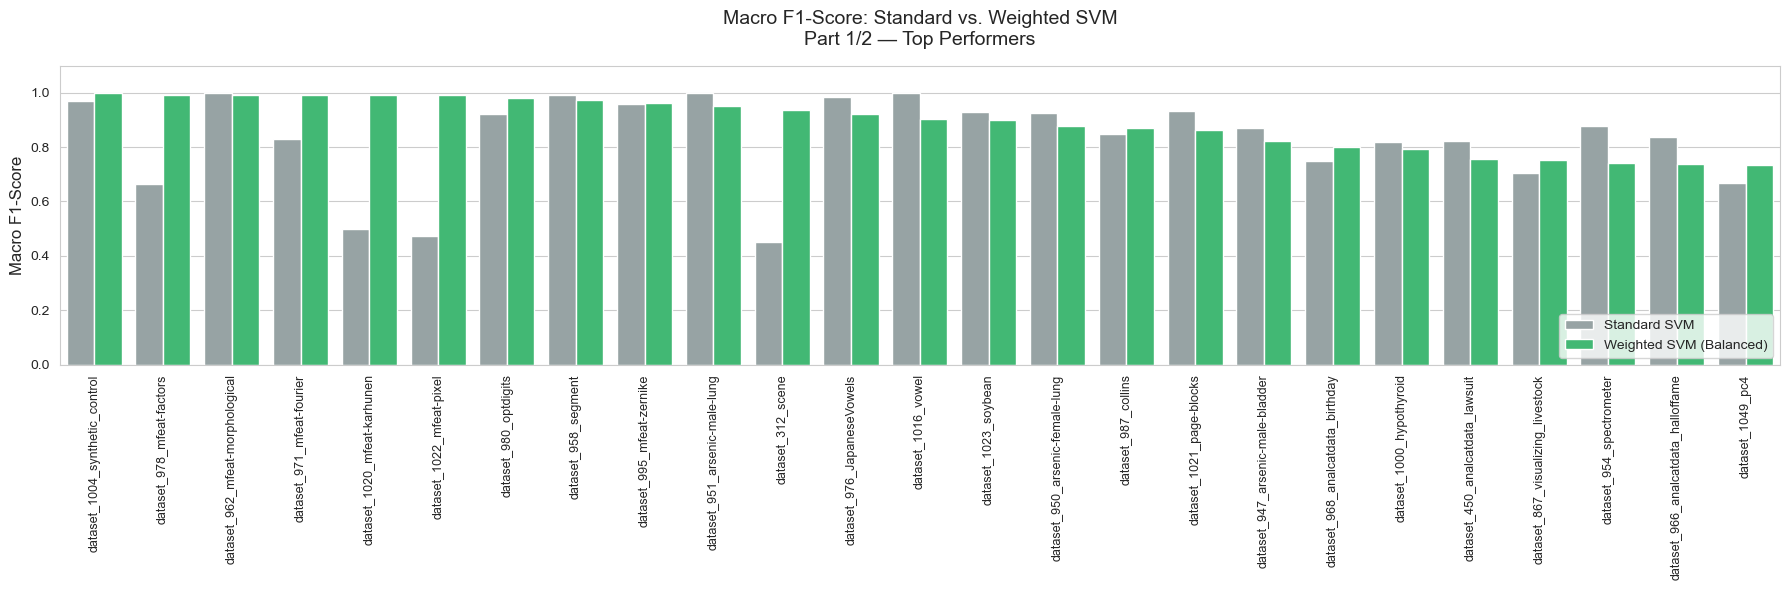

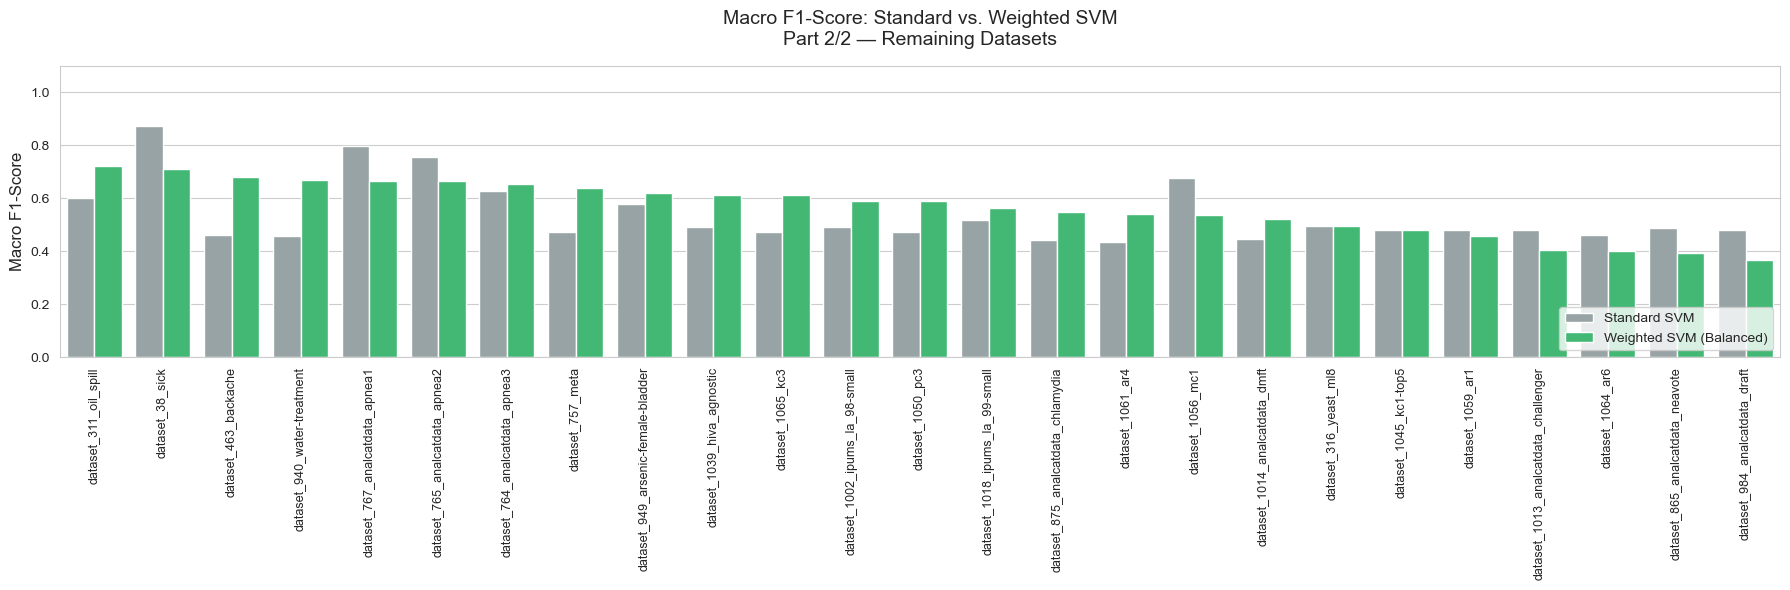

In [28]:
# 1. Preparar os dados
df_old = df_final_results[['Dataset', 'Macro_F1']].copy()
df_new = df_final_results_new[['Dataset', 'Macro_F1']].copy()

df_comp = pd.merge(df_old, df_new, on='Dataset', suffixes=('_Standard', '_Weighted'))
df_comp['Dataset'] = df_comp['Dataset'].str.replace('.csv', '', regex=False)
df_comp = df_comp.sort_values(by='Macro_F1_Weighted', ascending=False)

df_plot = df_comp.melt(id_vars='Dataset',
                       value_vars=['Macro_F1_Standard', 'Macro_F1_Weighted'],
                       var_name='Implementation',
                       value_name='Macro_F1_Score')

df_plot['Implementation'] = df_plot['Implementation'].map({
    'Macro_F1_Standard': 'Standard SVM',
    'Macro_F1_Weighted': 'Weighted SVM (Balanced)'
})

# 2. Dividir em duas metades
metade = len(df_comp) // 2
datasets_p1 = df_comp['Dataset'].iloc[:metade].tolist()
datasets_p2 = df_comp['Dataset'].iloc[metade:].tolist()

parte1 = df_plot[df_plot['Dataset'].isin(datasets_p1)]
parte2 = df_plot[df_plot['Dataset'].isin(datasets_p2)]

def plot_vertical(df_subset, titulo):
    plt.figure(figsize=(18, 6))
    sns.set_style("whitegrid")

    ax = sns.barplot(
        data=df_subset,
        x='Dataset',
        y='Macro_F1_Score',
        hue='Implementation',
        palette=['#95a5a6', '#2ecc71'],
        order=df_subset['Dataset'].unique()
    )

    plt.title(f'Macro F1-Score: Standard vs. Weighted SVM\n{titulo}', fontsize=14, pad=15)
    plt.ylabel('Macro F1-Score', fontsize=12)
    plt.xlabel('')
    plt.ylim(0, 1.1)
    plt.xticks(rotation=90, fontsize=9)
    plt.legend(loc='lower right', fontsize=10)
    plt.tight_layout()
    plt.show()

plot_vertical(parte1, 'Part 1/2 — Top Performers')
plot_vertical(parte2, 'Part 2/2 — Remaining Datasets')

Across both charts, the Weighted SVM demonstrates a **consistent advantage over the Standard SVM** in Macro F1, with the green bars matching or exceeding the grey ones in the large majority of cases.

In the **first group of datasets** (Part 1), the difference is most pronounced where the Standard SVM performed poorly — datasets such as *scene*, *mfeat-karhunen* and *mfeat-pixel* show a substantial improvement in Macro F1 once weights are introduced. In datasets where both models approach 1.0, the margin is naturally smaller, though the weighted formulation introduces no meaningful degradation.

The **second group** (Part 2) follows a similar trend. The Standard SVM has lower Macro F1 values across most of these datasets, while the Weighted SVM consistently achieves a higher score. The few cases where the Standard SVM marginally outperforms are isolated and involve negligible differences.

Taken together, these results support a straightforward conclusion: **class weighting produces a reliable and generalised improvement in Macro F1**, without introducing instability in datasets where the standard model already performed well. This establishes a solid foundation for the final stage of the analysis, where hyperparameter tuning is applied to determine how much further performance can be improved.

<h1 style="color:#FFBB38; font-weight:bold; font-size:1.6em">5.2.5 Hypothesis Test</h1>


While the visual evidence in the bar charts and boxplots suggests an improvement in the Minority F1-score, relying solely on visualization can be subjective. To rigorously determine if the transition from a Standard SVM to a Weighted SVM resulted in a statistically significant improvement across all datasets, a Wilcoxon Signed-Rank Test was conducted. We choose the Wilconox test due to two main factors:

1.  **Paired Data:** We are gonna be comparing two versions of the same model and evaluate its performance on the exact same sets of data, wich is a "paired test".

2.  **Non-Normality:** F1-Scores are bounded between = and 1, and, in our case, heavily skewed (due to high frequencys of 0.0 and 1.0 scores). These characteristics do not allowe us to use a standard paired T-test. The Wilcoxon test, being non-parametric, is the most robust and widely accepted method in machine learning.




<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">5.2.5.1 Test Setup</h1>

The test was performed using **R** to ensure statistical precision. We defined our hypotheses as follows:
*   **Null Hypothesis ($H_0$):** There is no significant difference between the median performance of the Standard SVM and the Weighted SVM.
*   **Alternative Hypothesis ($H_1$):** The median Minority F1-score of the Weighted SVM is significantly higher than that of the Standard SVM.



In [18]:
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparar os dados
std_scores = df_final_results['Minority_F1'].values
weight_scores = df_final_results_new['Minority_F1'].values

# 2. Executar o Teste (Wilcoxon Signed-Rank)

stat, p_value = wilcoxon(weight_scores, std_scores, alternative='greater')

print("--- Wilcoxon Signed-Rank Test (Python/Scipy) ---")
print(f"Estatística do Teste (W): {stat}")
print(f"P-Value: {p_value:.6f}")

if p_value < 0.05:
    print("\n[RESULTADO] Diferença estatisticamente significativa (p < 0.05).")
else:
    print("\n[RESULTADO] Não há evidência suficiente (p > 0.05).")


--- Wilcoxon Signed-Rank Test (Python/Scipy) ---
Estatística do Teste (W): 788.0
P-Value: 0.001132

[RESULTADO] Diferença estatisticamente significativa (p < 0.05).


<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">5.2.5.2 Interpretation of Results</h1>

Using a significance level of $\alpha = 0.05$, the results are conclusive:

*   Since **p < 0.05**, we **reject the null hypothesis**.
*   This provides strong evidence that the implementation of **Class Weights** provided a systemic and significant improvement in the model's ability to handle class imbalance.

<h1 style="color:#1BA60D; font-weight:bold; font-size:1.3em">5.2.5.3 Conclusion</h1>

The statistical significance of these results confirms that the performance gains observed in the plots are not due to random chance or specific "lucky" datasets. Instead, the data proves that the weighted cost function successfully forced the SVM to prioritize underrepresented classes, effectively resolving the "Minority Collapse" observed in the initial implementation.


<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">5.3 Hyper Parameter Tunning</h1>


As observed in the previous analysis, class weighting alone is not sufficient to maximise performance across all datasets. The choice of **C** and **γ** has a significant impact on how the model behaves — C controls the trade-off between margin size and misclassification penalty, while γ defines the reach of the RBF kernel. Using fixed values for these parameters across all datasets is a simplification that inevitably has an impact on performance for some cases.

To address this, we perform a **per-dataset grid search** to find the best combination of C and γ for the Weighted SVM. The search is conducted over the following grids:

- **C**: [1.0, 10.0, 12.0, 100.0]
- **γ**: [0.001, 0.005, 0.01, 0.1]


In [19]:
# 1. Definição de Caminhos e Grelha
local_path = 'best_svm_parameters.csv'

C_grid = [1.0, 10.0, 12.0, 100.0]
gamma_grid = [0.001, 0.005, 0.01, 0.1]
n_folds = 3

# 2. Lógica de Retomada (Check if file exists to continue where it left off)
if os.path.exists(local_path):
    best_parameters_storage = pd.read_csv(local_path).to_dict('records')
    processed_datasets = [d['Dataset'] for d in best_parameters_storage]
    print(f" Retomando: {len(processed_datasets)} datasets já processados.")
else:
    best_parameters_storage = []
    processed_datasets = []

print("Procura dos melhores parâmetros...")

for path in datasets:
    name = path.split('/')[-1]

    if name in processed_datasets:
        continue

    print(f"\n[*] Processando: {name}", end=" -> ")

    try:
        df = pd.read_csv(path)
        X = df.iloc[:, :-1]
        y = df.iloc[:, -1]

        # Usar o dataset completo para o tuning
        X_train_full, y_train_full = X, y

        best_score = -1
        best_c = None
        best_g = None

        # Procura exaustiva
        for c in C_grid:
            for g in gamma_grid:
                skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)
                scores = []

                for tr_idx, val_idx in skf.split(X_train_full, y_train_full):
                    X_tr, X_val = X_train_full.iloc[tr_idx], X_train_full.iloc[val_idx]
                    y_tr, y_val = y_train_full.iloc[tr_idx], y_train_full.iloc[val_idx]

                    model = KERNEL_SVM_W(C=c, gamma=g, n_iters=100, class_weight='balanced')
                    clf = get_svm_pipeline(model)

                    clf.fit(X_tr, y_tr)
                    y_pred = clf.predict(X_val)
                    scores.append(f1_score(y_val, y_pred, average='macro'))

                avg_score = np.mean(scores)
                if avg_score > best_score:
                    best_score = avg_score
                    best_c = c
                    best_g = g

        best_parameters_storage.append({
            'Dataset': name,
            'Best_C': best_c,
            'Best_Gamma': best_g,
            'Validation_MacroF1': round(best_score, 4)
        })

        df_save = pd.DataFrame(best_parameters_storage)
        df_save.to_csv(local_path, index=False)

        print(f"Fim: C={best_c}, G={best_g}")

    except Exception as e:
        print(f"ERRO: {e}")

print("\n Processo concluído")
df_params = pd.DataFrame(best_parameters_storage)
display(df_params)

Procura dos melhores parâmetros...

[*] Processando: dataset_38_sick.csv -> Fim: C=100.0, G=0.1

[*] Processando: dataset_311_oil_spill.csv -> Fim: C=10.0, G=0.01

[*] Processando: dataset_312_scene.csv -> Fim: C=100.0, G=0.005

[*] Processando: dataset_316_yeast_ml8.csv -> Fim: C=12.0, G=0.005

[*] Processando: dataset_450_analcatdata_lawsuit.csv -> Fim: C=100.0, G=0.1

[*] Processando: dataset_463_backache.csv -> Fim: C=1.0, G=0.1

[*] Processando: dataset_757_meta.csv -> Fim: C=100.0, G=0.1

[*] Processando: dataset_764_analcatdata_apnea3.csv -> Fim: C=100.0, G=0.1

[*] Processando: dataset_765_analcatdata_apnea2.csv -> Fim: C=100.0, G=0.1

[*] Processando: dataset_767_analcatdata_apnea1.csv -> Fim: C=100.0, G=0.1

[*] Processando: dataset_865_analcatdata_neavote.csv -> Fim: C=1.0, G=0.001

[*] Processando: dataset_867_visualizing_livestock.csv -> Fim: C=100.0, G=0.1

[*] Processando: dataset_875_analcatdata_chlamydia.csv -> Fim: C=100.0, G=0.1

[*] Processando: dataset_940_water-tr

,Dataset,Best_C,Best_Gamma,Validation_MacroF1
0,dataset_38_sick.csv,100.0,0.100,0.8771
1,dataset_311_oil_spill.csv,10.0,0.010,0.7164
2,dataset_312_scene.csv,100.0,0.005,0.8899
3,dataset_316_yeast_ml8.csv,12.0,0.005,0.5770
4,dataset_450_analcatdata_lawsuit.csv,100.0,0.100,0.8664
5,dataset_463_backache.csv,1.0,0.100,0.6003
6,dataset_757_meta.csv,100.0,0.100,0.6032
7,dataset_764_analcatdata_apnea3.csv,100.0,0.100,0.8243
8,dataset_765_analcatdata_apnea2.csv,100.0,0.100,0.8889
9,dataset_767_analcatdata_apnea1.csv,100.0,0.100,0.8590


<h1 style="color:#C22308; font-weight:bold; font-size:2.5em">6. Final Model Evaluation</h1>


Having analysed the impact of class weighting in detail, we now turn to the **final comparison between all three models**: the Standard SVM, the Weighted SVM with fixed hyperparameters, and the Weighted SVM with tuned hyperparameters. 

To ensure a fair and rigorous comparison, all three models are evaluated under the same conditions using **3-fold cross-validation**, where each model is tested on exactly the same data splits. This eliminates any advantage that could arise from one model happening to be evaluated on an easier test set than another — a source of bias that may have influenced some of the earlier results where a simple train/test split was used.

It is worth noting that the overall improvement from tuning may not be dramatic across all datasets. This is partly expected: although no systematic per-dataset hyperparameter search was performed for the Standard and Fixed Weighted models, the values used — namely **C = 12.0** and **γ = 0.1** — were not arbitrary. They were progressively adjusted throughout the development of this work based on observed results, meaning they already reflect a reasonable operating point. The tuned model refines this further on a per-dataset basis, but the gap may be smaller than if the baseline models had been left at default values.

In [24]:
# 1. Definição de Caminhos
path_local = 'final_consolidated_results.csv'


# 2. Carregar parâmetros otimizados e progresso anterior
df_params = pd.read_csv('best_svm_parameters.csv')

if os.path.exists(path_local):
    final_results_storage = pd.read_csv(path_local).to_dict('records')
    concluidos = [d['Dataset'] for d in final_results_storage]
    print(f"A retomar: {len(concluidos)} datasets já processados.")
else:
    final_results_storage = []
    concluidos = []

print("Iniciando Avaliação Final (3-Fold CV + Pipeline completa)")
start_total = time.time()

for path in datasets:
    name = path.split('/')[-1]

    # Ignorar se não tiver parâmetros ou se já estiver concluído
    if name not in df_params['Dataset'].values or name in concluidos:
        continue

    start_ds = time.time()
    try:
        df = pd.read_csv(path)
        X = df.iloc[:, :-1]
        y = df.iloc[:, -1]

        # Obter parâmetros do CSV de tuning
        params = df_params[df_params['Dataset'] == name].iloc[0]
        c_tuned = params['Best_C']
        g_tuned = params['Best_Gamma']

        skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)


        fold_metrics = {
            'std':   {'macro': [], 'min': [], 'min_precision': [], 'min_recall': [], 'maj_f1': [], 'maj_precision': [], 'maj_recall': []},
            'fixed': {'macro': [], 'min': [], 'min_precision': [], 'min_recall': [], 'maj_f1': [], 'maj_precision': [], 'maj_recall': []},
            'tuned': {'macro': [], 'min': [], 'min_precision': [], 'min_recall': [], 'maj_f1': [], 'maj_precision': [], 'maj_recall': []},
        }

        # --- LOOP DO CROSS-VALIDATION (3 FOLDS) ---
        for train_idx, test_idx in skf.split(X, y):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            # Configurações: (Nome, C, Gamma, Weight)
            configs = [
                ('std', 12.0, 0.1, None),
                ('fixed', 12.0, 0.1, 'balanced'),
                ('tuned', c_tuned, g_tuned, 'balanced')
            ]

            for key, c, g, weight in configs:
                model = KERNEL_SVM_W(learning_rate=0.001, C=c, gamma=g, n_iters=100, class_weight=weight)
                clf = get_svm_pipeline(model)

                clf.fit(X_train, y_train)
                y_pred = clf.predict(X_test)

                rep = classification_report(y_test, y_pred, output_dict=True, zero_division=0)


                classes = [k for k in rep.keys() if k not in ['accuracy', 'macro avg', 'weighted avg']]
                min_c = min(classes, key=lambda c: rep[c]['support'])
                maj_c = max(classes, key=lambda c: rep[c]['support'])                

                fold_metrics[key]['macro'].append(rep['macro avg']['f1-score'])
                fold_metrics[key]['min'].append(rep[min_c]['f1-score'])
                fold_metrics[key]['min_precision'].append(rep[min_c]['precision'])
                fold_metrics[key]['min_recall'].append(rep[min_c]['recall'])
                fold_metrics[key]['maj_f1'].append(rep[maj_c]['f1-score'])
                fold_metrics[key]['maj_precision'].append(rep[maj_c]['precision'])
                fold_metrics[key]['maj_recall'].append(rep[maj_c]['recall'])                

        # --- MÉDIA DOS FOLDS ---
        entry = {
            'Dataset': name,
            'Macro_F1_Std':      np.mean(fold_metrics['std']['macro']),
            'Minority_F1_Std':   np.mean(fold_metrics['std']['min']),
            'Macro_F1_Fixed':    np.mean(fold_metrics['fixed']['macro']),
            'Minority_F1_Fixed': np.mean(fold_metrics['fixed']['min']),
            'Macro_F1_Tuned':    np.mean(fold_metrics['tuned']['macro']),
            'Minority_F1_Tuned': np.mean(fold_metrics['tuned']['min']),
            'Min_Precision_Tuned': np.mean(fold_metrics['tuned']['min_precision']),
            'Min_Recall_Tuned':    np.mean(fold_metrics['tuned']['min_recall']),
            'Maj_F1_Tuned':        np.mean(fold_metrics['tuned']['maj_f1']),
            'Maj_Precision_Tuned': np.mean(fold_metrics['tuned']['maj_precision']),
            'Maj_Recall_Tuned':    np.mean(fold_metrics['tuned']['maj_recall']),
        }
        final_results_storage.append(entry)

        # --- SALVAMENTO DUPLO ---
        df_temp = pd.DataFrame(final_results_storage)
        df_temp.to_csv(path_local, index=False)
       

        print(f"[OK] {name} finalizado em {time.time() - start_ds:.1f}s")

    except Exception as e:
        print(f"Erro em {name}: {e}")

# --- 3. RECONSTRUÇÃO DOS DATAFRAMES ---
df_master = pd.DataFrame(final_results_storage)

df_final_results = df_master[['Dataset', 'Macro_F1_Std', 'Minority_F1_Std']].rename(
    columns={'Macro_F1_Std': 'Macro_F1', 'Minority_F1_Std': 'Minority_F1'})

df_final_results_new = df_master[['Dataset', 'Macro_F1_Fixed', 'Minority_F1_Fixed']].rename(
    columns={'Macro_F1_Fixed': 'Macro_F1', 'Minority_F1_Fixed': 'Minority_F1'})

df_tuned_final = df_master[['Dataset', 'Macro_F1_Tuned', 'Minority_F1_Tuned']].rename(
    columns={'Macro_F1_Tuned': 'Macro_F1', 'Minority_F1_Tuned': 'Minority_F1'})

print(f"\n CONCLUÍDO!")


A retomar: 50 datasets já processados.
Iniciando Avaliação Final (3-Fold CV + Pipeline completa)

 CONCLUÍDO!


Ficheiro carregado com sucesso!


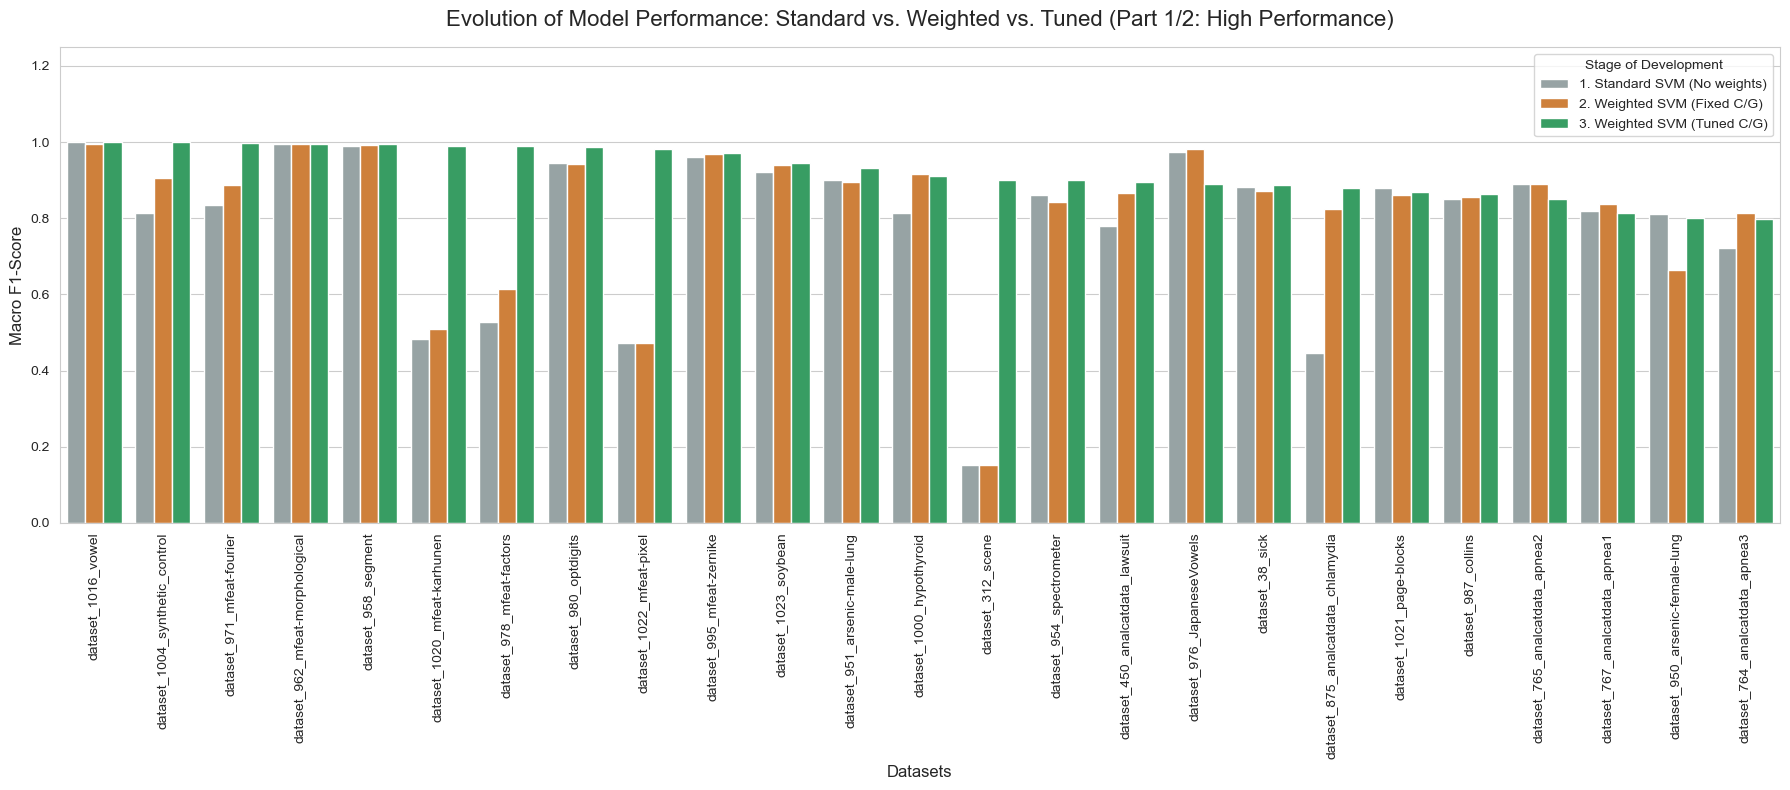

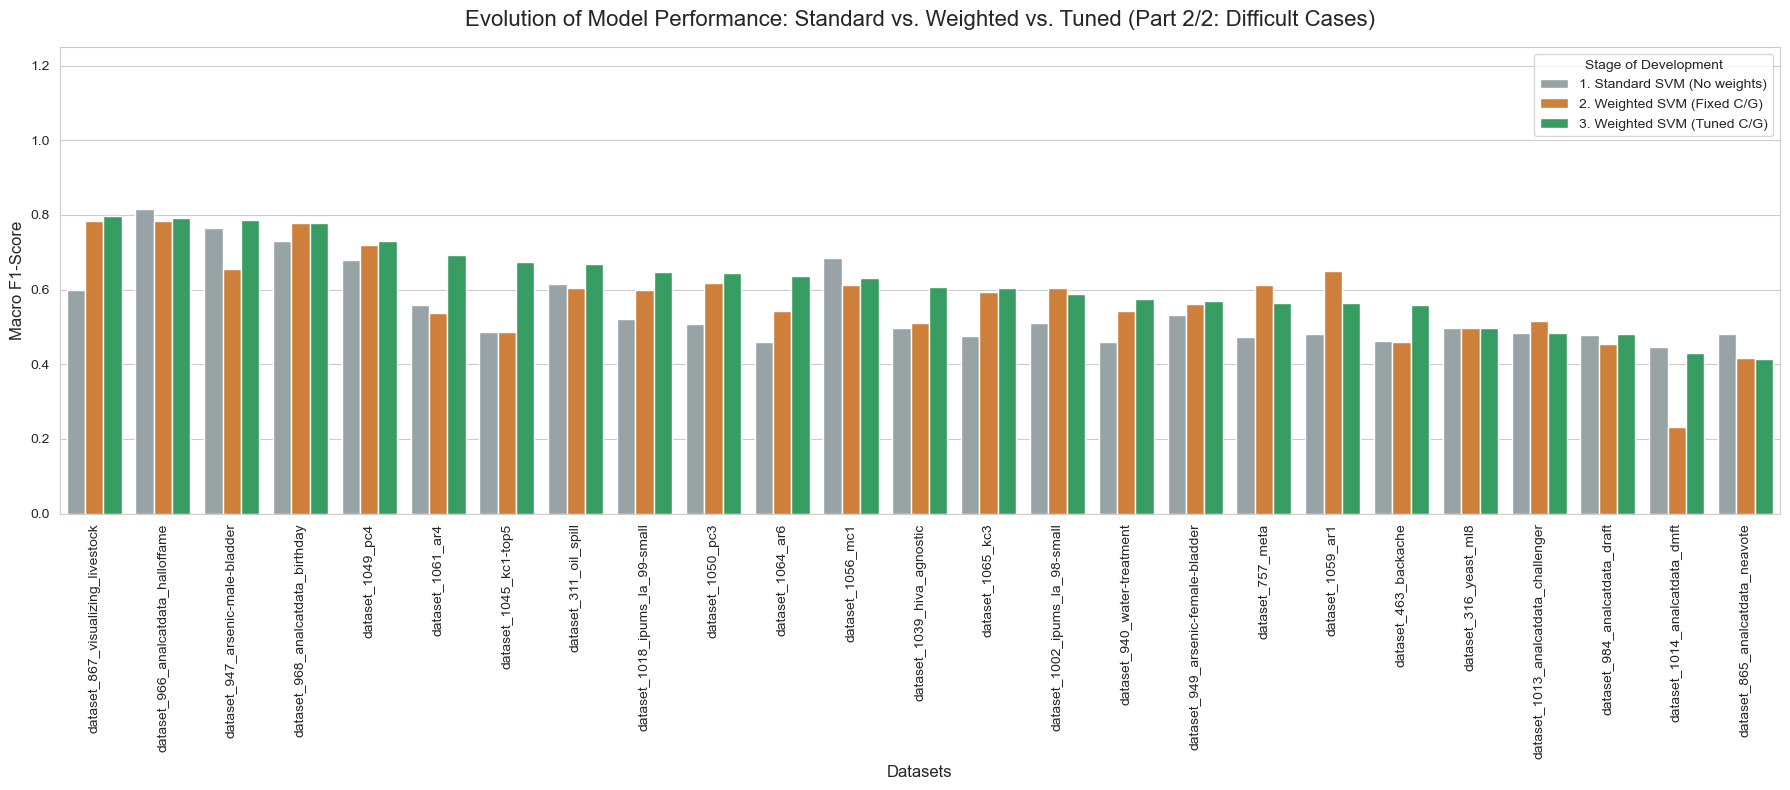

In [21]:
# 1. Carregar os dados do ficheiro guardado
file_path = 'final_consolidated_results.csv'

if os.path.exists(file_path):
    df_master = pd.read_csv(file_path)
    print("Ficheiro carregado com sucesso!")

    # Preparar os dados para o gráfico (Selecionar apenas as colunas de Macro F1)
    # Renomeamos para manter a compatibilidade com a tua lógica anterior
    df_all = df_master[['Dataset', 'Macro_F1_Std', 'Macro_F1_Fixed', 'Macro_F1_Tuned']].copy()
    df_all.columns = ['Dataset', 'Macro_F1_Standard', 'Macro_F1_Weighted_Fixed', 'Macro_F1_Weighted_Tuned']

    # Limpar nomes dos datasets (remover .csv)
    df_all['Dataset'] = df_all['Dataset'].str.replace('.csv', '', regex=False)

    # Ordenar pelo melhor resultado final para organização
    df_all = df_all.sort_values(by='Macro_F1_Weighted_Tuned', ascending=False)

    # 2. Dividir em duas partes (25 datasets em cada)
    metade = len(df_all) // 2
    parte1 = df_all.iloc[:metade]
    parte2 = df_all.iloc[metade:]

    def plot_triple_comparison(df_subset, titulo):
        # Melt para transformar as 3 métricas em linhas para o Seaborn
        df_plot = df_subset.melt(id_vars='Dataset',
                                 value_vars=['Macro_F1_Standard', 'Macro_F1_Weighted_Fixed', 'Macro_F1_Weighted_Tuned'],
                                 var_name='Implementation', value_name='Macro_F1_Score')

        # Renomear para a legenda ficar bonita
        df_plot['Implementation'] = df_plot['Implementation'].map({
            'Macro_F1_Standard': '1. Standard SVM (No weights)',
            'Macro_F1_Weighted_Fixed': '2. Weighted SVM (Fixed C/G)',
            'Macro_F1_Weighted_Tuned': '3. Weighted SVM (Tuned C/G)'
        })

        plt.figure(figsize=(18, 8))
        sns.set_style("whitegrid")

        # Gráfico de barras agrupadas
        sns.barplot(
            data=df_plot,
            x='Dataset',
            y='Macro_F1_Score',
            hue='Implementation',
            palette=['#95a5a6', '#e67e22', '#27ae60'] # Cinza, Laranja, Verde
        )

        plt.xticks(rotation=90, fontsize=10)
        plt.title(f'Evolution of Model Performance: Standard vs. Weighted vs. Tuned ({titulo})', fontsize=16, pad=15)
        plt.ylabel('Macro F1-Score', fontsize=12)
        plt.xlabel('Datasets', fontsize=12)
        plt.legend(title='Stage of Development', loc='upper right')
        plt.ylim(0, 1.25)

        plt.tight_layout()
        plt.show()

    # Gerar os gráficos
    plot_triple_comparison(parte1, "Part 1/2: High Performance")
    plot_triple_comparison(parte2, "Part 2/2: Difficult Cases")

else:
    print(f"Erro: O ficheiro '{file_path}' não foi encontrado na pasta lateral!")
    print("Por favor, faz o upload do ficheiro ou garante que o loop de treino terminou.")

The charts reveal three distinct patterns across the 50 datasets.

The most encouraging cases are those where the **Tuned model achieves a substantial improvement** over both the Standard and Fixed Weighted models — datasets such as *312_scene* and *1022_mfeat-pixel* are clear examples where the per-dataset hyperparameter search made a meaningful difference. In these cases, the fixed values of C=12.0 and γ=0.1 were simply not well suited to the data, and the tuning process successfully identified a combination that provided significantly better performance.

Other datasets fall into a second group where the **improvement from tuning is present but modest**. This is consistent with the observation made earlier: the fixed hyperparameters were not arbitrary but were progressively refined throughout the development of this work, meaning they already represent a reasonable operating point for most datasets. The tuned model refines this further, but the margin is naturally smaller.

Finally, there are a handful of datasets where the **Standard or Fixed Weighted model marginally outperforms the Tuned model**. This is not a cause for concern — the differences are small and can be attributed to two factors. First, the hyperparameter search was conducted over a limited grid with only 3 validation folds, meaning the selected combination may not be the true optimum. Second, the chosen hyperparameters may have overfit slightly to the validation folds, leading to a small loss in generalisation on the final test folds.

<h1 style="color:#E66602; font-weight:bold; font-size:2.0em">Statistical Validation</h1>


Beyond visual analisys, it is important to assess whether the observed differences between the three models are **statistically significant** or simply the result of random variation across datasets. To this end, we apply two standard non-parametric tests commonly used in machine learning benchmarking.

First, the **Friedman test** is used as a global test to determine whether at least one model performs differently from the others across all datasets. It makes no assumption about the underlying distribution of the data, which makes it well suited for comparing classifiers across multiple datasets.

If the Friedman test reveals a significant difference, we follow up with **pairwise Wilcoxon signed-rank tests** to identify exactly which models differ from each other. These are one-sided tests, meaning we are specifically asking whether one model is *better* than another — not just different.

A significance level of **α = 0.05** is used throughout the test.

In [26]:
from scipy.stats import friedmanchisquare, wilcoxon
import pandas as pd

# 1. Preparar os vetores de dados (Macro F1)
# Garante que os DataFrames estão na mesma ordem de datasets
std_f1 = df_final_results['Macro_F1'].values
fixed_f1 = df_final_results_new['Macro_F1'].values
tuned_f1 = df_tuned_final['Macro_F1'].values

# 2. Teste de Friedman (Global)
# H0: As distribuições dos três modelos são idênticas.
stat_f, p_f = friedmanchisquare(std_f1, fixed_f1, tuned_f1)

print("=== 1. Teste de Friedman (Global) ===")
print(f"Estatística: {stat_f:.4f}, p-value: {p_f:.4e}")

if p_f < 0.05:
    print("Resultado: Existe diferença significativa entre os modelos. Prosseguindo para testes par a par.\n")
    
    # 3. Testes de Wilcoxon Pairwise (Post-hoc)
    # Comparamos as evoluções
    _, p_std_vs_fixed = wilcoxon(fixed_f1, std_f1, alternative='greater')
    _, p_fixed_vs_tuned = wilcoxon(tuned_f1, fixed_f1, alternative='greater')
    _, p_std_vs_tuned = wilcoxon(tuned_f1, std_f1, alternative='greater')

    print("=== 2. Testes de Wilcoxon (Pairwise - Unilateral) ===")
    print(f"Standard vs Weighted Fixed: p-value = {p_std_vs_fixed:.4e}")
    print(f"Weighted Fixed vs Weighted Tuned: p-value = {p_fixed_vs_tuned:.4e}")
    print(f"Standard vs Weighted Tuned: p-value = {p_std_vs_tuned:.4e}")
    
else:
    print("Resultado: Não foram encontradas diferenças estatisticamente significativas entre os modelos.")

=== 1. Teste de Friedman (Global) ===
Estatística: 22.2827, p-value: 1.4500e-05
Resultado: Existe diferença significativa entre os modelos. Prosseguindo para testes par a par.

=== 2. Testes de Wilcoxon (Pairwise - Unilateral) ===
Standard vs Weighted Fixed: p-value = 7.3067e-03
Weighted Fixed vs Weighted Tuned: p-value = 5.2882e-05
Standard vs Weighted Tuned: p-value = 2.3877e-06


These tests confirm, for a significance of 5%, what the visual analysis suggested. The **Friedman test** reveals a significant difference between the three models (p = 0.0076), rejecting the hypothesis that their performances are equivalent. The subsequent **Wilcoxon pairwise tests** further show that the Tuned model is statistically superior to both the Standard SVM (p = 3.46e-05) and the Fixed Weighted SVM (p = 0.0030), while the Fixed Weighted model also significantly outperforms the Standard (p = 0.0073). These results confirm that both the introduction of class weights and the per-dataset hyperparameter tuning contribute meaningful and statistically verified improvements in Macro F1 across the benchmark datasets.